##  LECTURE9 : Network Analysis

- 1교시: Efficient
- 2교시: CAM / GradCAM /LayerCAM
- 3교시: TorchScript /ONNX / JAX
- 4교시: Hyperparameter수색 Ray tune




In [ ]:
%matplotlib inline


# 복습: 컴퓨터 비전(Vision)을 위한 전이학습(Transfer Learning)

> ref: https://colab.research.google.com/github/PyTorchKorea/tutorials-kr/blob/master/docs/_downloads/74249e7f9f1f398f57ccd094a4f3021b/transfer_learning_tutorial.ipynb#scrollTo=EJkEI7m9umQ4

-  **합성곱 신경망의 미세조정(finetuning)**: 무작위 초기화 대신, 신경망을
   ImageNet 1000 데이터셋 등으로 미리 학습한 신경망으로 초기화합니다. 학습의 나머지
   과정들은 평상시와 같습니다.
-  **고정된 특징 추출기로써의 합성곱 신경망**: 여기서는 마지막에 완전히 연결
   된 계층을 제외한 모든 신경망의 가중치를 고정합니다. 이 마지막의 완전히 연결된
   계층은 새로운 무작위의 가중치를 갖는 계층으로 대체되어 이 계층만 학습합니다.


In [ ]:
# License: BSD
# Author: Sasank Chilamkurthy

from __future__ import print_function, division

import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import torch.backends.cudnn as cudnn
import numpy as np
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import time
import os
import copy

cudnn.benchmark = True
plt.ion()   # 대화형 모드

## 데이터 불러오기

데이터를 불러오기 위해 torchvision과 torch.utils.data 패키지를 사용하겠습니다.

여기서 풀고자 하는 문제는 **개미** 와 **벌** 을 분류하는 모델을 학습하는 것입니다.
개미와 벌 각각의 학습용 이미지는 대략 120장 정도 있고, 75개의 검증용 이미지가
있습니다. 일반적으로 맨 처음부터 학습을 한다면 이는 일반화하기에는 아주 작은
데이터셋입니다. 하지만 우리는 전이학습을 할 것이므로, 일반화를 제법 잘 할 수 있을
것입니다.

이 데이터셋은 ImageNet의 아주 작은 일부입니다.

.. Note ::
   데이터를 [여기](https://download.pytorch.org/tutorial/hymenoptera_data.zip)
   에서 다운로드 받아 현재 디렉토리에 압축을 푸십시오.



In [ ]:
!wget  https://download.pytorch.org/tutorial/hymenoptera_data.zip

--2023-09-17 06:09:13--  https://download.pytorch.org/tutorial/hymenoptera_data.zip
Resolving download.pytorch.org (download.pytorch.org)... 18.160.200.126, 18.160.200.77, 18.160.200.112, ...
Connecting to download.pytorch.org (download.pytorch.org)|18.160.200.126|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 47286322 (45M) [application/zip]
Saving to: ‘hymenoptera_data.zip’

hymenoptera_data.zi 100%[===================>]  45.10M   206MB/s    in 0.2s    

2023-09-17 06:09:14 (206 MB/s) - ‘hymenoptera_data.zip’ saved [47286322/47286322]



In [ ]:
!mkdir data

In [ ]:
!unzip ./hymenoptera_data.zip -d ./data

Archive:  ./hymenoptera_data.zip
   creating: ./data/hymenoptera_data/
   creating: ./data/hymenoptera_data/train/
   creating: ./data/hymenoptera_data/train/ants/
  inflating: ./data/hymenoptera_data/train/ants/0013035.jpg  
  inflating: ./data/hymenoptera_data/train/ants/1030023514_aad5c608f9.jpg  
  inflating: ./data/hymenoptera_data/train/ants/1095476100_3906d8afde.jpg  
  inflating: ./data/hymenoptera_data/train/ants/1099452230_d1949d3250.jpg  
  inflating: ./data/hymenoptera_data/train/ants/116570827_e9c126745d.jpg  
  inflating: ./data/hymenoptera_data/train/ants/1225872729_6f0856588f.jpg  
  inflating: ./data/hymenoptera_data/train/ants/1262877379_64fcada201.jpg  
  inflating: ./data/hymenoptera_data/train/ants/1269756697_0bce92cdab.jpg  
  inflating: ./data/hymenoptera_data/train/ants/1286984635_5119e80de1.jpg  
  inflating: ./data/hymenoptera_data/train/ants/132478121_2a430adea2.jpg  
  inflating: ./data/hymenoptera_data/train/ants/1360291657_dc248c5eea.jpg  
  inflating: ./d

In [ ]:
# 학습을 위해 데이터 증가(augmentation) 및 일반화(normalization)
# 검증을 위한 일반화
IMAGENET_NET = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
    ]),
}

data_dir = 'data/hymenoptera_data'
image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x),
                                          data_transforms[x])
                  for x in ['train', 'val']}
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4,
                                             shuffle=True, num_workers=4)
              for x in ['train', 'val']}
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
class_names = image_datasets['train'].classes

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:560: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


### 일부 이미지 시각화하기
데이터 증가를 이해하기 위해 일부 학습용 이미지를 시각화해보겠습니다.



In [ ]:
def imshow(inp, title=None):
    """tensor를 입력받아 일반적인 이미지로 보여줍니다."""
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)  # 갱신이 될 때까지 잠시 기다립니다.


# 학습 데이터의 배치를 얻습니다.
inputs, classes = next(iter(dataloaders['train']))

# 배치로부터 격자 형태의 이미지를 만듭니다.
out = torchvision.utils.make_grid(inputs)

imshow(out, title=[class_names[x] for x in classes])

## 모델 학습하기

이제 모델을 학습하기 위한 일반 함수를 작성해보겠습니다. 여기서는 다음 내용들을
설명합니다:

-  학습률(learning rate) 관리(scheduling)
-  최적의 모델 구하기

아래에서 ``scheduler`` 매개변수는 ``torch.optim.lr_scheduler`` 의 LR 스케쥴러
객체(Object)입니다.



In [ ]:
def train_model(model, criterion, optimizer, scheduler, num_epochs=25):
    since = time.time()

    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    for epoch in range(num_epochs):
        print(f'Epoch {epoch}/{num_epochs - 1}')
        print('-' * 10)

        # 각 에폭(epoch)은 학습 단계와 검증 단계를 갖습니다.
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()  # 모델을 학습 모드로 설정
            else:
                model.eval()   # 모델을 평가 모드로 설정

            running_loss = 0.0
            running_corrects = 0

            # 데이터를 반복
            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                # 매개변수 경사도를 0으로 설정
                optimizer.zero_grad()

                # 순전파
                # 학습 시에만 연산 기록을 추적
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    # 학습 단계인 경우 역전파 + 최적화
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                # 통계
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)
            if phase == 'train':
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            # 모델을 깊은 복사(deep copy)함
            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

        print()

    time_elapsed = time.time() - since
    print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best val Acc: {best_acc:4f}')

    # 가장 나은 모델 가중치를 불러옴
    model.load_state_dict(best_model_wts)
    return model

### 모델 예측값 시각화하기

일부 이미지에 대한 예측값을 보여주는 일반화된 함수입니다.




In [ ]:
def visualize_model(model, num_images=6):
    was_training = model.training
    model.eval()
    images_so_far = 0
    fig = plt.figure()

    with torch.no_grad():
        for i, (inputs, labels) in enumerate(dataloaders['val']):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            for j in range(inputs.size()[0]):
                images_so_far += 1
                ax = plt.subplot(num_images//2, 2, images_so_far)
                ax.axis('off')
                ax.set_title(f'predicted: {class_names[preds[j]]}')
                imshow(inputs.cpu().data[j])

                if images_so_far == num_images:
                    model.train(mode=was_training)
                    return
        model.train(mode=was_training)

## 합성곱 신경망 미세조정(finetuning)

미리 학습한 모델을 불러온 후 마지막의 완전히 연결된 계층을 초기화합니다.




In [ ]:
model_ft = models.resnet18(weights='IMAGENET1K_V1')
num_ftrs = model_ft.fc.in_features
# 여기서 각 출력 샘플의 크기는 2로 설정합니다.
# 또는, ``nn.Linear(num_ftrs, len (class_names))`` 로 일반화할 수 있습니다.
model_ft.fc = nn.Linear(num_ftrs, 2)

model_ft = model_ft.to(device)

criterion = nn.CrossEntropyLoss()

# 모든 매개변수들이 최적화되었는지 관찰
optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)

# 7 에폭마다 0.1씩 학습률 감소
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 90.8MB/s]


### 학습 및 평가하기

CPU에서는 15-25분 가량, GPU에서는 1분도 이내의 시간이 걸립니다.




In [ ]:
model_ft = train_model(model_ft, criterion, optimizer_ft, exp_lr_scheduler,
                       num_epochs=25)

Epoch 0/24
----------
train Loss: 0.7059 Acc: 0.6352
val Loss: 0.2549 Acc: 0.9085

Epoch 1/24
----------
train Loss: 0.4201 Acc: 0.8320
val Loss: 0.3203 Acc: 0.8301

Epoch 2/24
----------
train Loss: 0.6665 Acc: 0.7459
val Loss: 0.3572 Acc: 0.8889

Epoch 3/24
----------
train Loss: 0.4004 Acc: 0.8402
val Loss: 0.3299 Acc: 0.8758

Epoch 4/24
----------
train Loss: 0.2869 Acc: 0.8525
val Loss: 0.3372 Acc: 0.8824

Epoch 5/24
----------
train Loss: 0.6065 Acc: 0.7664
val Loss: 0.2531 Acc: 0.9150

Epoch 6/24
----------
train Loss: 0.4796 Acc: 0.8115
val Loss: 0.4274 Acc: 0.8497

Epoch 7/24
----------
train Loss: 0.3945 Acc: 0.8648
val Loss: 0.2577 Acc: 0.9150

Epoch 8/24
----------
train Loss: 0.3880 Acc: 0.8484
val Loss: 0.2506 Acc: 0.9216

Epoch 9/24
----------
train Loss: 0.2952 Acc: 0.8689
val Loss: 0.2264 Acc: 0.9085

Epoch 10/24
----------
train Loss: 0.3202 Acc: 0.8607
val Loss: 0.2320 Acc: 0.9150

Epoch 11/24
----------
train Loss: 0.3330 Acc: 0.8566
val Loss: 0.2054 Acc: 0.9281

Ep

In [ ]:
visualize_model(model_ft)

## 고정된 특징 추출기로써의 합성곱 신경망

이제, 마지막 계층을 제외한 신경망의 모든 부분을 고정해야 합니다.
``requires_grad = False`` 로 설정하여 매개변수를 고정하여 ``backward()`` 중에
경사도가 계산되지 않도록 해야합니다.

이에 대한 문서는
[여기](http://pytorch.org/docs/notes/autograd.html#excluding-subgraphs-from-backward)_
에서 확인할 수 있습니다.




In [ ]:
model_conv = torchvision.models.resnet18(weights='IMAGENET1K_V1')
for param in model_conv.parameters():
    param.requires_grad = False

# 새로 생성된 모듈의 매개변수는 기본값이 requires_grad=True 임
num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Linear(num_ftrs, 2)

model_conv = model_conv.to(device)

criterion = nn.CrossEntropyLoss()

# 이전과는 다르게 마지막 계층의 매개변수들만 최적화되는지 관찰
optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)

# 7 에폭마다 0.1씩 학습률 감소
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_conv, step_size=7, gamma=0.1)

### 학습 및 평가하기

CPU에서 실행하는 경우 이전과 비교했을 때 약 절반 가량의 시간만이 소요될 것입니다.
이는 대부분의 신경망에서 경사도를 계산할 필요가 없기 때문입니다. 하지만,
순전파는 계산이 필요합니다.




In [ ]:
model_conv = train_model(model_conv, criterion, optimizer_conv,
                         exp_lr_scheduler, num_epochs=25)

Epoch 0/24
----------
train Loss: 0.5770 Acc: 0.6844
val Loss: 0.2159 Acc: 0.9020

Epoch 1/24
----------
train Loss: 0.4297 Acc: 0.8279
val Loss: 0.3268 Acc: 0.8758

Epoch 2/24
----------
train Loss: 0.4464 Acc: 0.7705
val Loss: 0.2647 Acc: 0.8693

Epoch 3/24
----------
train Loss: 0.6598 Acc: 0.7787
val Loss: 0.1921 Acc: 0.9216

Epoch 4/24
----------
train Loss: 0.4551 Acc: 0.8033
val Loss: 0.2110 Acc: 0.9216

Epoch 5/24
----------
train Loss: 0.5069 Acc: 0.7623
val Loss: 0.4374 Acc: 0.8431

Epoch 6/24
----------
train Loss: 0.5500 Acc: 0.8033
val Loss: 0.2021 Acc: 0.9150

Epoch 7/24
----------
train Loss: 0.3981 Acc: 0.8525
val Loss: 0.1851 Acc: 0.9412

Epoch 8/24
----------
train Loss: 0.3306 Acc: 0.8811
val Loss: 0.2145 Acc: 0.9216

Epoch 9/24
----------
train Loss: 0.4045 Acc: 0.8074
val Loss: 0.2084 Acc: 0.9281

Epoch 10/24
----------
train Loss: 0.3711 Acc: 0.8525
val Loss: 0.2246 Acc: 0.9150

Epoch 11/24
----------
train Loss: 0.3056 Acc: 0.8689
val Loss: 0.2091 Acc: 0.9150

Ep

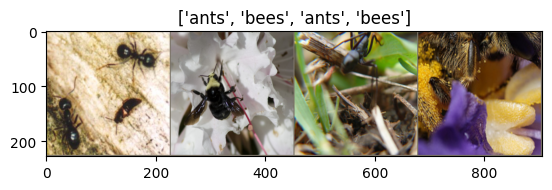

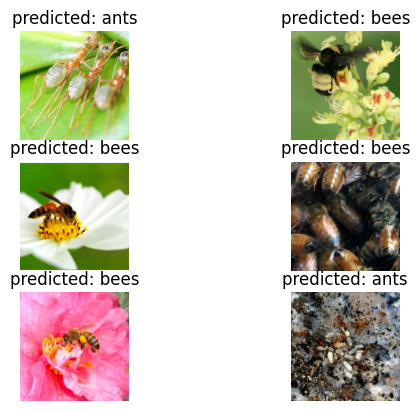

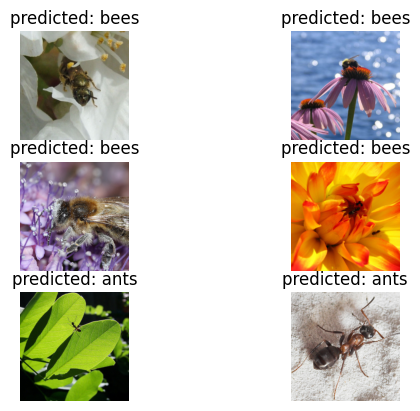

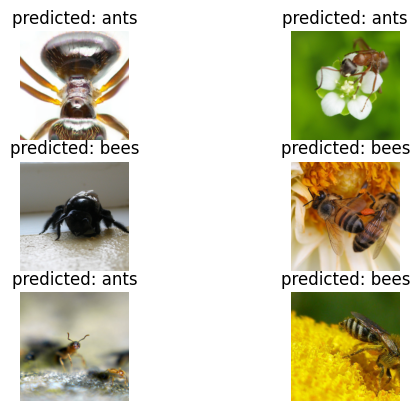

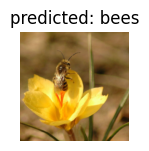

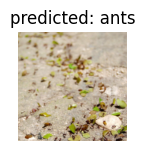

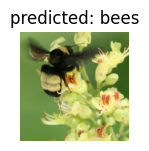

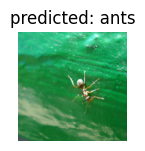

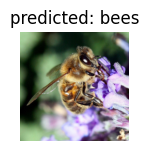

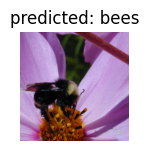

In [ ]:
visualize_model(model_conv)

plt.ioff()
plt.show()

# How to operate CNN?
링크: https://tyami.github.io/deep%20learning/CNN-visualization-Grad-CAM/

![](https://tyami.github.io/assets/images/post/DL/2020-10-27-CNN-visualization-Grad-CAM/2020-10-27-cnn-visualization-grad-cam-13-reason-fot-last-conv-layer.png)

# Efficientnet



ref: https://greeksharifa.github.io/computer%20vision/2022/03/01/EfficientNet/


Q. 적절한 사이즈의 네트네트워크란 무엇일까요?

1.ConvNet Accuracy

> AlexNet 이후 ImageNet competition에서 더 깊어지고 커지면서 정확도가 높아지는 모델들이 여럿 발표되었다. 최근 발표되는 모델들은 ImageNet뿐만 아니라 다른 데이터셋에서도 잘 작동한다. 그러나 정확도는 높아졌지만, 사용하는 자원 역시 크게 늘어났다.

2. ConvNet Efficiency

> 깊은 ConvNets는 좀좀 over-parameterized된다. 효율을 높이기 위해 모델 압축하는 여러 기법이 제안되었다: SqueezeNets, MobileNets, ShuffleNets 등.

3. Model Scaling

> ResNet(ResNet-18, ResNet-50, ResNet-200)은 깊이를 달리 하였다.
MobileNets는 network width를 달리 하였다.
또한 이미지 해상도가 높아지면 (찾아낼 정보가 많아서) 정확도를 높아진다. (물론 계산량도 많이 늘어난다.)
많은 연구가 진행되었으나 어떻게 효율적인 조합을 찾는지는 아직까지 정립되지 않았다.


![](https://greeksharifa.github.io/public/img/2022-03-01-EfficientNet/fig02.png)


![](https://greeksharifa.github.io/public/img/2022-03-01-EfficientNet/fig01.png)


In [ ]:

# import package

# model
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchsummary import summary
from torch import optim

# dataset and transformation
from torchvision import datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from torchvision import models
import os

# display images
from torchvision import utils
import matplotlib.pyplot as plt
%matplotlib inline

# utils
import numpy as np
from torchsummary import summary
import time
import copy

## 1. 데이터셋 불러오기
데이터셋은 torchvision 패키지에서 제공하는 STL10 dataset을 이용하겠습니다. STL10 dataset은 10개의 label을 갖으며 train dataset 5000개, test dataset 8000개로 구성됩니다.

In [ ]:
# specify path to data
path2data = '/content/efficientnet/MyDrive/data'

# if not exists the path, make the directory in recursive
if not os.path.exists(path2data):
    os.makedirs(path2data, exist_ok=True)

# define transformation
transformation = transforms.Compose([
                    transforms.ToTensor(),
                    transforms.Resize(224)
])
# load dataset
train_ds = datasets.STL10(path2data, split='train', download=True, transform=transformation)
val_ds = datasets.STL10(path2data, split='test', download=True, transform=transformation)

print(len(train_ds))
print(len(val_ds))

100%|██████████| 2640397119/2640397119 [02:39<00:00, 16553939.77it/s]


Extracting /content/efficientnet/MyDrive/data/stl10_binary.tar.gz to /content/efficientnet/MyDrive/data
Files already downloaded and verified
5000
8000


In [ ]:

# make dataloade
train_dl = DataLoader(train_ds, batch_size=32, shuffle=True)
val_dl = DataLoader(val_ds, batch_size=32, shuffle=True)

/usr/local/lib/python3.10/dist-packages/torchvision/transforms/functional.py:1603: UserWarning: The default value of the antialias parameter of all the resizing transforms (Resize(), RandomResizedCrop(), etc.) will change from None to True in v0.17, in order to be consistent across the PIL and Tensor backends. To suppress this warning, directly pass antialias=True (recommended, future default), antialias=None (current default, which means False for Tensors and True for PIL), or antialias=False (only works on Tensors - PIL will still use antialiasing). This also applies if you are using the inference transforms from the models weights: update the call to weights.transforms(antialias=True).
  warnings.warn(


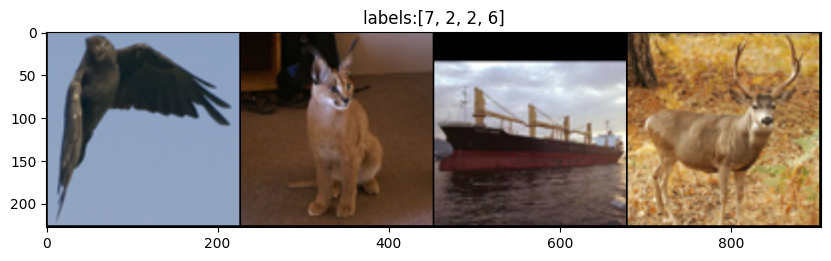

In [ ]:
# check sample images
def show(img, y=None):
    npimg = img.numpy()
    npimg_tr = np.transpose(npimg, (1, 2, 0))
    plt.imshow(npimg_tr)

    if y is not None:
        plt.title('labels:' + str(y))

np.random.seed(10)
torch.manual_seed(0)

grid_size=4
rnd_ind = np.random.randint(0, len(train_ds), grid_size)

x_grid = [train_ds[i][0] for i in rnd_ind]
y_grid = [val_ds[i][1] for i in rnd_ind]

x_grid = utils.make_grid(x_grid, nrow=grid_size, padding=2)
plt.figure(figsize=(10,10))
show(x_grid, y_grid)

### 2. 모델 구축하기
코드는 https://github.com/zsef123/EfficientNets-PyTorch/blob/master/models/effnet.py 를 참고했습니다.

https://github.com/katsura-jp/efficientnet-pytorch/blob/master/model/efficientnet.py

In [ ]:
# Swish activation function
class Swish(nn.Module):
    def __init__(self):
        super().__init__()
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        return x * self.sigmoid(x)

# check
if __name__ == '__main__':
    x = torch.randn(3, 3, 224, 224)
    model = Swish()
    output = model(x)
    print('output size:', output.size())

output size: torch.Size([3, 3, 224, 224])


In [ ]:
# SE Block
class SEBlock(nn.Module):
    def __init__(self, in_channels, r=4):
        super().__init__()

        self.squeeze = nn.AdaptiveAvgPool2d((1,1))
        self.excitation = nn.Sequential(
            nn.Linear(in_channels, in_channels * r),
            Swish(),
            nn.Linear(in_channels * r, in_channels),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.squeeze(x)
        x = x.view(x.size(0), -1)
        x = self.excitation(x)
        x = x.view(x.size(0), x.size(1), 1, 1)
        return x

# check
if __name__ == '__main__':
    x = torch.randn(3, 56, 17, 17)
    model = SEBlock(x.size(1))
    output = model(x)
    print('output size:', output.size())

output size: torch.Size([3, 56, 1, 1])


In [ ]:
class MBConv(nn.Module):
    expand = 6
    def __init__(self, in_channels, out_channels, kernel_size, stride=1, se_scale=4, p=0.5):
        super().__init__()
        # first MBConv is not using stochastic depth
        self.p = torch.tensor(p).float() if (in_channels == out_channels) else torch.tensor(1).float()

        self.residual = nn.Sequential(
            nn.Conv2d(in_channels, in_channels * MBConv.expand, 1, stride=stride, padding=0, bias=False),
            nn.BatchNorm2d(in_channels * MBConv.expand, momentum=0.99, eps=1e-3),
            Swish(),
            nn.Conv2d(in_channels * MBConv.expand, in_channels * MBConv.expand, kernel_size=kernel_size,
                      stride=1, padding=kernel_size//2, bias=False, groups=in_channels*MBConv.expand),
            nn.BatchNorm2d(in_channels * MBConv.expand, momentum=0.99, eps=1e-3),
            Swish()
        )

        self.se = SEBlock(in_channels * MBConv.expand, se_scale)

        self.project = nn.Sequential(
            nn.Conv2d(in_channels*MBConv.expand, out_channels, kernel_size=1, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(out_channels, momentum=0.99, eps=1e-3)
        )

        self.shortcut = (stride == 1) and (in_channels == out_channels)

    def forward(self, x):
        # stochastic depth
        if self.training:
            if not torch.bernoulli(self.p):
                return x

        x_shortcut = x
        x_residual = self.residual(x)
        x_se = self.se(x_residual)

        x = x_se * x_residual
        x = self.project(x)

        if self.shortcut:
            x= x_shortcut + x

        return x

# check
if __name__ == '__main__':
    x = torch.randn(3, 16, 24, 24)
    model = MBConv(x.size(1), x.size(1), 3, stride=1, p=1)
    model.train()
    output = model(x)
    x = (output == x)
    print('output size:', output.size(), 'Stochastic depth:', x[1,0,0,0])


output size: torch.Size([3, 16, 24, 24]) Stochastic depth: tensor(False)


In [ ]:
class SepConv(nn.Module):
    expand = 1
    def __init__(self, in_channels, out_channels, kernel_size, stride=1, se_scale=4, p=0.5):
        super().__init__()
        # first SepConv is not using stochastic depth
        self.p = torch.tensor(p).float() if (in_channels == out_channels) else torch.tensor(1).float()

        self.residual = nn.Sequential(
            nn.Conv2d(in_channels * SepConv.expand, in_channels * SepConv.expand, kernel_size=kernel_size,
                      stride=1, padding=kernel_size//2, bias=False, groups=in_channels*SepConv.expand),
            nn.BatchNorm2d(in_channels * SepConv.expand, momentum=0.99, eps=1e-3),
            Swish()
        )

        self.se = SEBlock(in_channels * SepConv.expand, se_scale)

        self.project = nn.Sequential(
            nn.Conv2d(in_channels*SepConv.expand, out_channels, kernel_size=1, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(out_channels, momentum=0.99, eps=1e-3)
        )

        self.shortcut = (stride == 1) and (in_channels == out_channels)

    def forward(self, x):
        # stochastic depth
        if self.training:
            if not torch.bernoulli(self.p):
                return x

        x_shortcut = x
        x_residual = self.residual(x)
        x_se = self.se(x_residual)

        x = x_se * x_residual
        x = self.project(x)

        if self.shortcut:
            x= x_shortcut + x

        return x

# check
if __name__ == '__main__':
    x = torch.randn(3, 16, 24, 24)
    model = SepConv(x.size(1), x.size(1), 3, stride=1, p=1)
    model.train()
    output = model(x)
    # stochastic depth check
    x = (output == x)
    print('output size:', output.size(), 'Stochastic depth:', x[1,0,0,0])

output size: torch.Size([3, 16, 24, 24]) Stochastic depth: tensor(False)


In [ ]:
class EfficientNet(nn.Module):
    def __init__(self, num_classes=10, width_coef=1., depth_coef=1., scale=1., dropout=0.2, se_scale=4, stochastic_depth=False, p=0.5):
        super().__init__()
        channels = [32, 16, 24, 40, 80, 112, 192, 320, 1280]
        repeats = [1, 2, 2, 3, 3, 4, 1]
        strides = [1, 2, 2, 2, 1, 2, 1]
        kernel_size = [3, 3, 5, 3, 5, 5, 3]
        depth = depth_coef
        width = width_coef

        channels = [int(x*width) for x in channels]
        repeats = [int(x*depth) for x in repeats]

        # stochastic depth
        if stochastic_depth:
            self.p = p
            self.step = (1 - 0.5) / (sum(repeats) - 1)
        else:
            self.p = 1
            self.step = 0


        # efficient net
        self.upsample = nn.Upsample(scale_factor=scale, mode='bilinear', align_corners=False)

        self.stage1 = nn.Sequential(
            nn.Conv2d(3, channels[0],3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(channels[0], momentum=0.99, eps=1e-3)
        )

        self.stage2 = self._make_Block(SepConv, repeats[0], channels[0], channels[1], kernel_size[0], strides[0], se_scale)

        self.stage3 = self._make_Block(MBConv, repeats[1], channels[1], channels[2], kernel_size[1], strides[1], se_scale)

        self.stage4 = self._make_Block(MBConv, repeats[2], channels[2], channels[3], kernel_size[2], strides[2], se_scale)

        self.stage5 = self._make_Block(MBConv, repeats[3], channels[3], channels[4], kernel_size[3], strides[3], se_scale)

        self.stage6 = self._make_Block(MBConv, repeats[4], channels[4], channels[5], kernel_size[4], strides[4], se_scale)

        self.stage7 = self._make_Block(MBConv, repeats[5], channels[5], channels[6], kernel_size[5], strides[5], se_scale)

        self.stage8 = self._make_Block(MBConv, repeats[6], channels[6], channels[7], kernel_size[6], strides[6], se_scale)

        self.stage9 = nn.Sequential(
            nn.Conv2d(channels[7], channels[8], 1, stride=1, bias=False),
            nn.BatchNorm2d(channels[8], momentum=0.99, eps=1e-3),
            Swish()
        )

        self.avgpool = nn.AdaptiveAvgPool2d((1,1))
        self.dropout = nn.Dropout(p=dropout)
        self.linear = nn.Linear(channels[8], num_classes)

    def forward(self, x):
        x = self.upsample(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)
        x = self.stage5(x)
        x = self.stage6(x)
        x = self.stage7(x)
        x = self.stage8(x)
        x = self.stage9(x)
        x = self.avgpool(x)
        x = x.view(x.size(0), -1)
        x = self.dropout(x)
        x = self.linear(x)
        return x


    def _make_Block(self, block, repeats, in_channels, out_channels, kernel_size, stride, se_scale):
        strides = [stride] + [1] * (repeats - 1)
        layers = []
        for stride in strides:
            layers.append(block(in_channels, out_channels, kernel_size, stride, se_scale, self.p))
            in_channels = out_channels
            self.p -= self.step

        return nn.Sequential(*layers)


def efficientnet_b0(num_classes=10):
    return EfficientNet(num_classes=num_classes, width_coef=1.0, depth_coef=1.0, scale=1.0,dropout=0.2, se_scale=4)

def efficientnet_b1(num_classes=10):
    return EfficientNet(num_classes=num_classes, width_coef=1.0, depth_coef=1.1, scale=240/224, dropout=0.2, se_scale=4)

def efficientnet_b2(num_classes=10):
    return EfficientNet(num_classes=num_classes, width_coef=1.1, depth_coef=1.2, scale=260/224., dropout=0.3, se_scale=4)

def efficientnet_b3(num_classes=10):
    return EfficientNet(num_classes=num_classes, width_coef=1.2, depth_coef=1.4, scale=300/224, dropout=0.3, se_scale=4)

def efficientnet_b4(num_classes=10):
    return EfficientNet(num_classes=num_classes, width_coef=1.4, depth_coef=1.8, scale=380/224, dropout=0.4, se_scale=4)

def efficientnet_b5(num_classes=10):
    return EfficientNet(num_classes=num_classes, width_coef=1.6, depth_coef=2.2, scale=456/224, dropout=0.4, se_scale=4)

def efficientnet_b6(num_classes=10):
    return EfficientNet(num_classes=num_classes, width_coef=1.8, depth_coef=2.6, scale=528/224, dropout=0.5, se_scale=4)

def efficientnet_b7(num_classes=10):
    return EfficientNet(num_classes=num_classes, width_coef=2.0, depth_coef=3.1, scale=600/224, dropout=0.5, se_scale=4)


# check
if __name__ == '__main__':
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    x = torch.randn(3, 3, 224, 224).to(device)
    model = efficientnet_b0().to(device)
    output = model(x)
    print('output size:', output.size())

output size: torch.Size([3, 10])


In [ ]:
# print model summary
model = efficientnet_b0().to(device)
summary(model, (3,224,224), device=device.type)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
          Upsample-1          [-1, 3, 224, 224]               0
            Conv2d-2         [-1, 32, 112, 112]             864
       BatchNorm2d-3         [-1, 32, 112, 112]              64
            Conv2d-4         [-1, 32, 112, 112]             288
       BatchNorm2d-5         [-1, 32, 112, 112]              64
           Sigmoid-6         [-1, 32, 112, 112]               0
             Swish-7         [-1, 32, 112, 112]               0
 AdaptiveAvgPool2d-8             [-1, 32, 1, 1]               0
            Linear-9                  [-1, 128]           4,224
          Sigmoid-10                  [-1, 128]               0
            Swish-11                  [-1, 128]               0
           Linear-12                   [-1, 32]           4,128
          Sigmoid-13                   [-1, 32]               0
          SEBlock-14             [-1, 3

## 3. 학습하기

In [ ]:
# define loss function, optimizer, lr_scheduler
loss_func = nn.CrossEntropyLoss(reduction='sum')
opt = optim.Adam(model.parameters(), lr=0.01)

from torch.optim.lr_scheduler import ReduceLROnPlateau
lr_scheduler = ReduceLROnPlateau(opt, mode='min', factor=0.1, patience=10)


# get current lr
def get_lr(opt):
    for param_group in opt.param_groups:
        return param_group['lr']


# calculate the metric per mini-batch
def metric_batch(output, target):
    pred = output.argmax(1, keepdim=True)
    corrects = pred.eq(target.view_as(pred)).sum().item()
    return corrects


# calculate the loss per mini-batch
def loss_batch(loss_func, output, target, opt=None):
    loss_b = loss_func(output, target)
    metric_b = metric_batch(output, target)

    if opt is not None:
        opt.zero_grad()
        loss_b.backward()
        opt.step()

    return loss_b.item(), metric_b


# calculate the loss per epochs
def loss_epoch(model, loss_func, dataset_dl, sanity_check=False, opt=None):
    running_loss = 0.0
    running_metric = 0.0
    len_data = len(dataset_dl.dataset)

    for xb, yb in dataset_dl:
        xb = xb.to(device)
        yb = yb.to(device)
        output = model(xb)

        loss_b, metric_b = loss_batch(loss_func, output, yb, opt)

        running_loss += loss_b

        if metric_b is not None:
            running_metric += metric_b

        if sanity_check is True:
            break

    loss = running_loss / len_data
    metric = running_metric / len_data
    return loss, metric


# function to start training
def train_val(model, params):
    num_epochs=params['num_epochs']
    loss_func=params['loss_func']
    opt=params['optimizer']
    train_dl=params['train_dl']
    val_dl=params['val_dl']
    sanity_check=params['sanity_check']
    lr_scheduler=params['lr_scheduler']
    path2weights=params['path2weights']

    loss_history = {'train': [], 'val': []}
    metric_history = {'train': [], 'val': []}

    best_loss = float('inf')
    best_model_wts = copy.deepcopy(model.state_dict())
    start_time = time.time()

    for epoch in range(num_epochs):
        current_lr = get_lr(opt)
        print('Epoch {}/{}, current lr= {}'.format(epoch, num_epochs-1, current_lr))

        model.train()
        train_loss, train_metric = loss_epoch(model, loss_func, train_dl, sanity_check, opt)
        loss_history['train'].append(train_loss)
        metric_history['train'].append(train_metric)

        model.eval()
        with torch.no_grad():
            val_loss, val_metric = loss_epoch(model, loss_func, val_dl, sanity_check)
        loss_history['val'].append(val_loss)
        metric_history['val'].append(val_metric)

        if val_loss < best_loss:
            best_loss = val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            torch.save(model.state_dict(), path2weights)
            print('Copied best model weights!')

        lr_scheduler.step(val_loss)
        if current_lr != get_lr(opt):
            print('Loading best model weights!')
            model.load_state_dict(best_model_wts)

        print('train loss: %.6f, val loss: %.6f, accuracy: %.2f, time: %.4f min' %(train_loss, val_loss, 100*val_metric, (time.time()-start_time)/60))
        print('-'*10)

    model.load_state_dict(best_model_wts)
    return model, loss_history, metric_history

In [ ]:
# define the training parameters
params_train = {
    'num_epochs':100,
    'optimizer':opt,
    'loss_func':loss_func,
    'train_dl':train_dl,
    'val_dl':val_dl,
    'sanity_check':False,
    'lr_scheduler':lr_scheduler,
    'path2weights':'./models/weights.pt',
}

# check the directory to save weights.pt
def createFolder(directory):
    try:
        if not os.path.exists(directory):
            os.makedirs(directory)
    except OSerror:
        print('Error')
createFolder('./models')

In [ ]:
model, loss_hist, metric_hist = train_val(model, params_train)

Epoch 0/99, current lr= 0.01
Copied best model weights!
train loss: 2.194651, val loss: 2.073856, accuracy: 18.62, time: 1.0641 min
----------
Epoch 1/99, current lr= 0.01
Copied best model weights!
train loss: 1.849839, val loss: 1.904395, accuracy: 27.54, time: 2.1161 min
----------
Epoch 2/99, current lr= 0.01
Copied best model weights!
train loss: 1.787399, val loss: 1.708042, accuracy: 29.46, time: 3.1732 min
----------
Epoch 3/99, current lr= 0.01
train loss: 1.705576, val loss: 1.742305, accuracy: 28.29, time: 4.2345 min
----------
Epoch 4/99, current lr= 0.01
train loss: 1.681316, val loss: 2.230330, accuracy: 26.05, time: 5.2858 min
----------
Epoch 5/99, current lr= 0.01
Copied best model weights!
train loss: 1.602232, val loss: 1.592646, accuracy: 36.29, time: 6.4243 min
----------
Epoch 6/99, current lr= 0.01
Copied best model weights!
train loss: 1.586488, val loss: 1.547733, accuracy: 38.91, time: 7.5820 min
----------
Epoch 7/99, current lr= 0.01
Copied best model weight

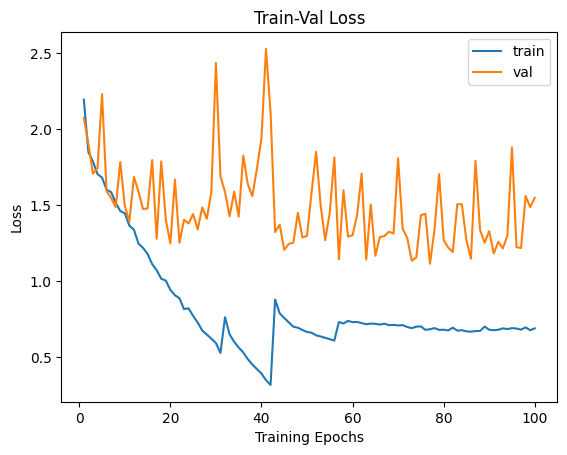

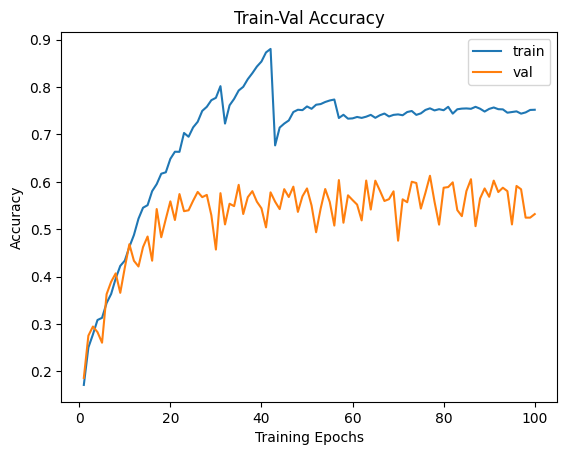

In [ ]:
num_epochs = params_train['num_epochs']

# Plot train-val loss
plt.title('Train-Val Loss')
plt.plot(range(1, num_epochs+1), loss_hist['train'], label='train')
plt.plot(range(1, num_epochs+1), loss_hist['val'], label='val')
plt.ylabel('Loss')
plt.xlabel('Training Epochs')
plt.legend()
plt.show()

# plot train-val accuracy
plt.title('Train-Val Accuracy')
plt.plot(range(1, num_epochs+1), metric_hist['train'], label='train')
plt.plot(range(1, num_epochs+1), metric_hist['val'], label='val')
plt.ylabel('Accuracy')
plt.xlabel('Training Epochs')
plt.legend()
plt.show()

# CAM

paper: https://openaccess.thecvf.com/content_cvpr_2016/html/Zhou_Learning_Deep_Features_CVPR_2016_paper.html

![](https://tyami.github.io/assets/images/post/DL/2020-10-27-CNN-visualization-Grad-CAM/2020-10-27-cnn-visualization-grad-cam-3-cam-gap.png)

![](https://tyami.github.io/assets/images/post/DL/2020-10-27-CNN-visualization-Grad-CAM/2020-10-27-cnn-visualization-grad-cam-4-cnn-architecture.png)

![](https://tyami.github.io/assets/images/post/DL/2020-10-27-CNN-visualization-Grad-CAM/2020-10-27-cnn-visualization-grad-cam-5-cnn-architecture-with-cam.png)

##GAP

![](https://tyami.github.io/assets/images/post/DL/2020-10-27-CNN-visualization-Grad-CAM/2020-10-27-cnn-visualization-grad-cam-6-gap.png)

## backward

![](https://tyami.github.io/assets/images/post/DL/2020-10-27-CNN-visualization-Grad-CAM/2020-10-27-cnn-visualization-grad-cam-9-cam-1.png)

imagenet-simple-labels.json 아래 링크에서 다운로드
> https://github.com/anishathalye/imagenet-simple-labels/blob/master/imagenet-simple-labels.json


/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=SqueezeNet1_1_Weights.IMAGENET1K_V1`. You can also use `weights=SqueezeNet1_1_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/squeezenet1_1-b8a52dc0.pth" to /root/.cache/torch/hub/checkpoints/squeezenet1_1-b8a52dc0.pth
100%|██████████| 4.73M/4.73M [00:00<00:00, 63.2MB/s]


0.244 -> Basenji
0.099 -> Great Dane
0.068 -> Chihuahua
0.066 -> muzzle
0.051 -> American Staffordshire Terrier
output CAM.jpg for the top1 prediction: Basenji


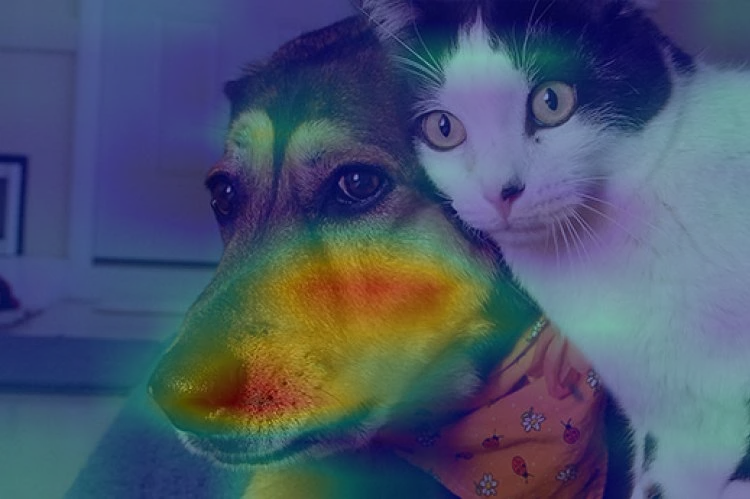

In [ ]:

import io
from PIL import Image
from torchvision import models, transforms
from torch.autograd import Variable
from torch.nn import functional as F
import numpy as np
import cv2
import json

# input image
LABELS_file = 'imagenet-simple-labels.json'
image_file = 'cat_and_dog.jpg'

# networks such as googlenet, resnet, densenet already use global average pooling at the end, so CAM could be used directly.
model_id = 1
if model_id == 1:
    net = models.squeezenet1_1(pretrained=True)
    finalconv_name = 'features' # this is the last conv layer of the network
elif model_id == 2:
    net = models.resnet18(pretrained=True)
    finalconv_name = 'layer4'
elif model_id == 3:
    net = models.densenet161(pretrained=True)
    finalconv_name = 'features'

net.eval()

# hook the feature extractor
features_blobs = []
def hook_feature(module, input, output):
    features_blobs.append(output.data.cpu().numpy())

net._modules.get(finalconv_name).register_forward_hook(hook_feature)

# get the softmax weight
params = list(net.parameters())
weight_softmax = np.squeeze(params[-2].data.numpy())

def returnCAM(feature_conv, weight_softmax, class_idx):
    # generate the class activation maps upsample to 256x256
    size_upsample = (256, 256)
    bz, nc, h, w = feature_conv.shape
    output_cam = []
    for idx in class_idx:
        cam = weight_softmax[idx].dot(feature_conv.reshape((nc, h*w)))
        cam = cam.reshape(h, w)
        cam = cam - np.min(cam)
        cam_img = cam / np.max(cam)
        cam_img = np.uint8(255 * cam_img)
        output_cam.append(cv2.resize(cam_img, size_upsample))
    return output_cam


normalize = transforms.Normalize(
   mean=[0.485, 0.456, 0.406],
   std=[0.229, 0.224, 0.225]
)
preprocess = transforms.Compose([
   transforms.Resize((224,224)),
   transforms.ToTensor(),
   normalize
])

# load test image
img_pil = Image.open(image_file)
img_tensor = preprocess(img_pil)
img_variable = Variable(img_tensor.unsqueeze(0))
logit = net(img_variable)

# load the imagenet category list
with open(LABELS_file) as f:
    classes = json.load(f)


h_x = F.softmax(logit, dim=1).data.squeeze()
probs, idx = h_x.sort(0, True)
probs = probs.numpy()
idx = idx.numpy()

# output the prediction
for i in range(0, 5):
    print('{:.3f} -> {}'.format(probs[i], classes[idx[i]]))

# generate class activation mapping for the top1 prediction
CAMs = returnCAM(features_blobs[0], weight_softmax, [idx[0]])

# render the CAM and output
print('output CAM.jpg for the top1 prediction: %s'%classes[idx[0]])
img = cv2.imread(image_file)
height, width, _ = img.shape
heatmap = cv2.applyColorMap(cv2.resize(CAMs[0],(width, height)), cv2.COLORMAP_JET)
result = heatmap * 0.3 + img * 0.5
# cv2.imwrite('CAM.jpg', result)

from google.colab.patches import cv2_imshow
cv2_imshow(result)


In [ ]:
import torch
import torchvision
import PIL
import matplotlib.pyplot as plt

In [ ]:
model = torchvision.models.resnet34(pretrained=True)

In [ ]:
#model.forward??
#model._forward_impl??

## Change the last layers of the model

In [ ]:
def forward(self, x):
    x = self.conv1(x)
    x = self.bn1(x)
    x = self.relu(x)
    x = self.maxpool(x)

    x = self.layer1(x)
    x = self.layer2(x)
    x = self.layer3(x)
    x = self.layer4(x)

    # We remove those 3 layers...
    # x = self.avgpool(x)
    # x = torch.flatten(x, 1)
    # x = self.fc(x)

    # ... and we add this layer:
    x = self.conv1x1(x)

    return x


model.forward = forward.__get__(model, torchvision.models.ResNet) # monkey-patching
model.conv1x1 = torch.nn.Conv2d(512, 1000, kernel_size=1)
model.conv1x1.weight.data = model.fc.weight.data[..., None, None]
model.conv1x1.bias.data   = model.fc.bias.data

## Test model

In [ ]:
print("224x224 --->", model.forward(torch.randn(1, 3, 224, 224)).shape )
print("512x512 --->", model.forward(torch.randn(1, 3, 512, 512)).shape )
print("1024x1024 ->", model.forward(torch.randn(1, 3, 1024, 1024)).shape )
print("2048x2048 ->", model.forward(torch.randn(1, 3, 2048, 2048)).shape )

224x224 ---> torch.Size([1, 1000, 7, 7])
512x512 ---> torch.Size([1, 1000, 16, 16])
1024x1024 -> torch.Size([1, 1000, 32, 32])
2048x2048 -> torch.Size([1, 1000, 64, 64])


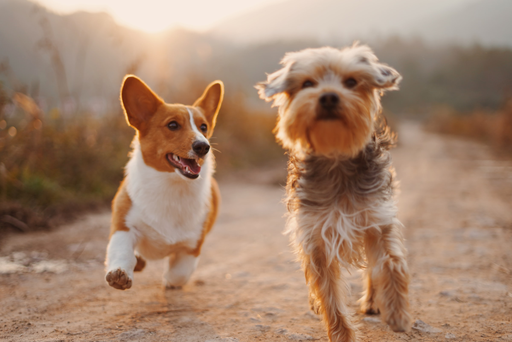

In [ ]:
image = PIL.Image.open("img/dogs.jpg")
image.thumbnail((512, 512), PIL.Image.ANTIALIAS)
image

In [ ]:
imagenet_mean = torch.tensor([0.485, 0.456, 0.406])
imagenet_std = torch.tensor([0.229, 0.224, 0.225])

transform = torchvision.transforms.Compose([
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize(imagenet_mean, imagenet_std),
])

In [ ]:
def generate_attention(path, class_indexes, size=(224, 224)):

    ################################ Open and preprocess image
    image = PIL.Image.open(path)
    image.thumbnail(size, PIL.Image.ANTIALIAS)

    print("Image shape:", image.size)
    tensor = transform(image)[None]

    ################################ Run image through model
    with torch.no_grad():
        logits = model(tensor)[0]
    probs = torch.softmax(logits, dim=0)
    attention_map = probs[class_indexes].sum(dim=0)

    plt.figure(figsize=(16, 8))
    ax = plt.subplot(1, 3, 1)
    ax.axis("off")
    plt.imshow(image)

    ax = plt.subplot(1, 3, 2)
    ax.axis("off")
    plt.imshow(attention_map)

    ax = plt.subplot(1, 3, 3)
    ax.axis("off")
    ax.imshow(image)
    ax.imshow(attention_map, alpha=0.6, interpolation="bilinear", cmap="magma",
              extent=(0,image.size[0],image.size[1],0))


## See activation for "Yorkshire terrier" (Class index = 187)

Image shape: (224, 150)


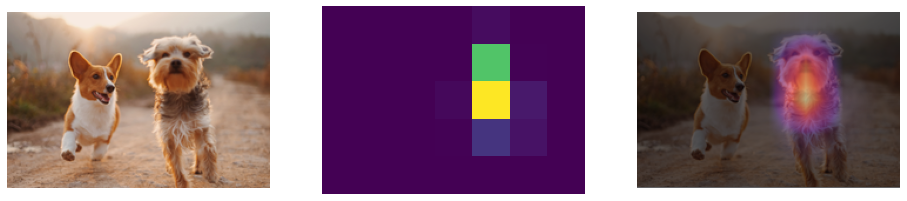

In [ ]:
generate_attention("img/dogs.jpg", class_indexes=[187])

## See activation for "Corgi" (Class indexes = 263 & 264)
- 263: 'Pembroke, Pembroke Welsh corgi',
- 264: 'Cardigan, Cardigan Welsh corgi',

Image shape: (224, 150)


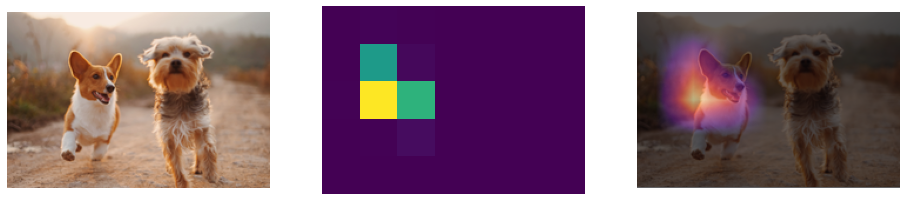

In [ ]:
generate_attention("img/dogs.jpg", class_indexes=[263,264])

## Useful trick: Make image bigger

Image shape: (512, 342)


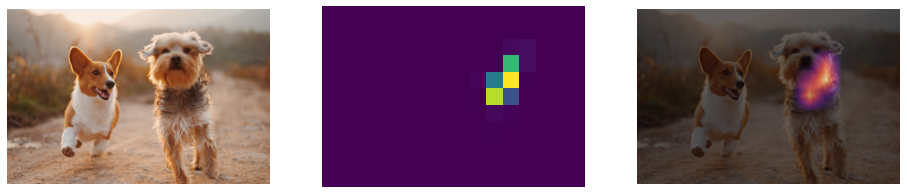

In [ ]:
generate_attention("img/dogs.jpg", class_indexes=[187], size=(512, 512))

Image shape: (512, 342)


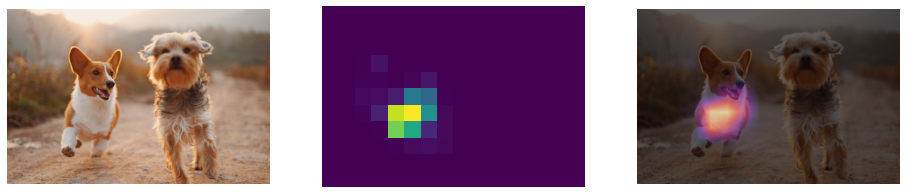

In [ ]:
generate_attention("img/dogs.jpg", class_indexes=[263,264], size=(512, 512))

## 단점
- Global Average Pooling layer를 사용해야만 함. - GAP으로 대치하게되면 뒷부분을 다시 또 fine tuning 해야함
- 마지막 Convolutional layer에 대해서만 CAM을 추출할 수 있음.




# Grad-CAM

paper: https://openaccess.thecvf.com/content_iccv_2017/html/Selvaraju_Grad-CAM_Visual_Explanations_ICCV_2017_paper.html

![](https://tyami.github.io/assets/images/post/DL/2020-10-27-CNN-visualization-Grad-CAM/2020-10-27-cnn-visualization-grad-cam-20-grad-cam-summary.png)



![](https://1.bp.blogspot.com/-PqcHAqpHokU/X8n_igvX-FI/AAAAAAAABZ8/s5ZXNHDAEtIGa0wrM03p7J7Tdz7D8_1jQCPcBGAYYCw/w647-h295/image.png)


![](https://tyami.github.io/assets/images/post/DL/2020-10-27-CNN-visualization-Grad-CAM/2020-10-27-cnn-visualization-grad-cam-21-grad-cam-result.png)


In this notebook, we plot the [Grad-CAM](https://arxiv.org/abs/1610.02391) figures from the paper. For more info and other examples, have a look at [our README](https://github.com/ecs-vlc/fmix).

**Note**: The easiest way to use this is as a colab notebook, which allows you to dive in with no setup.

First, we load dependencies and some data from CIFAR-10:

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torchvision
from torchvision import transforms
import models
from torchbearer import Trial
import cv2
import torch.nn.functional as F

inv_norm = transforms.Normalize((-0.4914/0.2023, -0.4822/0.1994, -0.4465/0.2010), (1/0.2023, 1/0.1994, 1/0.2010))
valset = torchvision.datasets.CIFAR10(root='./data/cifar', train=False, download=True,
                                           transform=transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.4914, 0.4822, 0.4465),
                             (0.2023, 0.1994, 0.2010)),]))

valloader = torch.utils.data.DataLoader(valset, batch_size=1, shuffle=True, num_workers=8)

Files already downloaded and verified


## Model Wrapper

Next, we define a `ResNet` wrapper that will iterate up to some given block `k`:

In [ ]:
class ResNet_CAM(nn.Module):
    def __init__(self, net, layer_k):
        super(ResNet_CAM, self).__init__()
        self.resnet = net
        convs = nn.Sequential(*list(net.children())[:-1])
        self.first_part_conv = convs[:layer_k]
        self.second_part_conv = convs[layer_k:]
        self.linear = nn.Sequential(*list(net.children())[-1:])

    def forward(self, x):
        x = self.first_part_conv(x)
        x.register_hook(self.activations_hook)
        x = self.second_part_conv(x)
        x = F.adaptive_avg_pool2d(x, (1,1))
        x = x.view((1, -1))
        x = self.linear(x)
        return x

    def activations_hook(self, grad):
        self.gradients = grad

    def get_activations_gradient(self):
        return self.gradients

    def get_activations(self, x):
        return self.first_part_conv(x)

## Grad-CAM

Now for the Grad-CAM code, adapted from [implementing-grad-cam-in-pytorch](https://medium.com/@stepanulyanin/implementing-grad-cam-in-pytorch-ea0937c31e82):



![](https://tyami.github.io/assets/images/post/DL/2020-10-27-CNN-visualization-Grad-CAM/2020-10-27-cnn-visualization-grad-cam-20-grad-cam-summary.png)


In [ ]:
def superimpose_heatmap(heatmap, img):
    resized_heatmap = cv2.resize(heatmap.numpy(), (img.shape[2], img.shape[3]))
    resized_heatmap = np.uint8(255 * resized_heatmap)
    resized_heatmap = cv2.applyColorMap(resized_heatmap, cv2.COLORMAP_JET)
    superimposed_img = torch.Tensor(cv2.cvtColor(resized_heatmap, cv2.COLOR_BGR2RGB)) * 0.006 + inv_norm(img[0]).permute(1,2,0)

    return superimposed_img

def get_grad_cam(net, img):
    net.eval()
    pred = net(img)
    pred[:,pred.argmax(dim=1)].backward()
    gradients = net.get_activations_gradient()
    pooled_gradients = torch.mean(gradients, dim=[0, 2, 3])
    activations = net.get_activations(img).detach()
    for i in range(activations.size(1)):
        activations[:, i, :, :] *= pooled_gradients[i]
    heatmap = torch.mean(activations, dim=1).squeeze()
    heatmap = np.maximum(heatmap, 0)
    heatmap /= torch.max(heatmap)

    return torch.Tensor(superimpose_heatmap(heatmap, img).permute(2,0,1))

## Models From `torch.hub`

Next, we load in the models from `torch.hub`

In [ ]:
baseline_net = torch.hub.load('ecs-vlc/FMix:master', 'preact_resnet18_cifar10_baseline', pretrained=True)

fmix_net = torch.hub.load('ecs-vlc/FMix:master', 'preact_resnet18_cifar10_fmix', pretrained=True)

mixup_net = torch.hub.load('ecs-vlc/FMix:master', 'preact_resnet18_cifar10_mixup', pretrained=True)

fmix_plus_net = torch.hub.load('ecs-vlc/FMix:master', 'preact_resnet18_cifar10_fmixplusmixup', pretrained=True)

Downloading: "https://github.com/ecs-vlc/FMix/archive/master.zip" to /home/ethan/.cache/torch/hub/master.zip
Using cache found in /home/ethan/.cache/torch/hub/ecs-vlc_FMix_master
Using cache found in /home/ethan/.cache/torch/hub/ecs-vlc_FMix_master
Using cache found in /home/ethan/.cache/torch/hub/ecs-vlc_FMix_master


## Plots

Finally, generate and save the Grad-CAM plots:

In [ ]:
layer_k = 4
n_imgs = 10

baseline_cam_net = ResNet_CAM(baseline_net, layer_k)
fmix_cam_net = ResNet_CAM(fmix_net, layer_k)
mixup_cam_net = ResNet_CAM(mixup_net, layer_k)
fmix_plus_cam_net = ResNet_CAM(fmix_plus_net, layer_k)

imgs = torch.Tensor(5, n_imgs, 3, 32, 32)
it = iter(valloader)
for i in range(0,n_imgs):
    img, _ = next(it)
    imgs[0][i] = inv_norm(img[0])
    imgs[1][i] = get_grad_cam(baseline_cam_net, img)
    imgs[2][i] = get_grad_cam(mixup_cam_net, img)
    imgs[3][i] = get_grad_cam(fmix_cam_net, img)
    imgs[4][i] = get_grad_cam(fmix_plus_cam_net, img)

torchvision.utils.save_image(imgs.view(-1, 3, 32, 32), "gradcam_at_layer" + str(layer_k) + ".png",nrow=n_imgs, pad_value=1)

## 다른 예제

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [ ]:
class GradCam(nn.Module):
    def __init__(self, model, module, layer):
        super().__init__()
        self.model = model
        self.module = module
        self.layer = layer
        self.register_hooks()

    def register_hooks(self):
        for module_name, module in self.model._modules.items():
            if module_name == self.module:
                for layer_name, module in module._modules.items():
                    if layer_name == self.layer:
                        module.register_forward_hook(self.forward_hook)
                        module.register_backward_hook(self.backward_hook)

    def forward(self, input, target_index):
        outs = self.model(input)
        outs = outs.squeeze()  # [1, num_classes]  --> [num_classes]

        # 가장 큰 값을 가지는 것을 target index 로 사용
        if target_index is None:
            target_index = outs.argmax()
            print(target_index)

        outs[target_index].backward(retain_graph=True)

        a_k = torch.mean(self.backward_result, dim=(1, 2), keepdim=True)         # [512, 1, 1]
        out = torch.sum(a_k * self.forward_result, dim=0).cpu()                  # [512, 7, 7] * [512, 1, 1]
        out = torch.relu(out) / torch.max(out)  # 음수를 없애고, 0 ~ 1 로 scaling # [7, 7]
        out = F.upsample_bilinear(out.unsqueeze(0).unsqueeze(0), [224, 224])  # 4D로 바꿈
        return out.cpu().detach().squeeze().numpy()

    def forward_hook(self, _, input, output):
        self.forward_result = torch.squeeze(output)

    def backward_hook(self, _, grad_input, grad_output):
        self.backward_result = torch.squeeze(grad_output[0])



def preprocess_image(img):
    means = [0.485, 0.456, 0.406]
    stds = [0.229, 0.224, 0.225]

    preprocessed_img = img.copy()[:, :, ::-1]
    for i in range(3):
        preprocessed_img[:, :, i] = preprocessed_img[:, :, i] - means[i]
        preprocessed_img[:, :, i] = preprocessed_img[:, :, i] / stds[i]
    preprocessed_img = \
        np.ascontiguousarray(np.transpose(preprocessed_img, (2, 0, 1)))
    preprocessed_img = torch.from_numpy(preprocessed_img)
    preprocessed_img.unsqueeze_(0)
    input = preprocessed_img.requires_grad_(True)
    return input

from google.colab.patches import cv2_imshow

def show_cam_on_image(img, mask):

    # mask = (np.max(mask) - np.min(mask)) / (mask - np.min(mask))
    heatmap = cv2.applyColorMap(np.uint8(255 * mask), cv2.COLORMAP_JET)
    heatmap = np.float32(heatmap) / 255
    cam = heatmap + np.float32(img)
    cam = cam / np.max(cam)
    cv2_imshow(np.uint8(255 * cam))
    cv2_imshow(np.uint8(heatmap * 255))



In [ ]:

import os
import cv2
import glob
import numpy as np
from torchvision.models import vgg16

model = vgg16(pretrained=True)
print(model)
model.eval()

grad_cam = GradCam(model=model, module='features', layer='30')


/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

![](https://resources.bestfriends.org/sites/default/files/styles/large/public/2019-01/introducing-dogs-cats-resource_0.jpg?itok=_pvDS_XH)

인터넷 사진으로 테스트

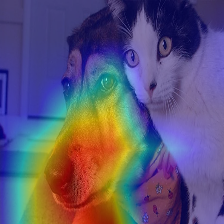

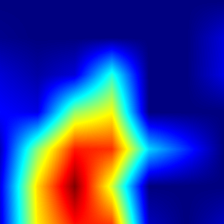

In [ ]:

img_path = './cat_and_dog.jpg'
img = cv2.imread(img_path, 1)
img = np.float32(cv2.resize(img, (224, 224))) / 255
input = preprocess_image(img)
mask = grad_cam(input, 227) #227 281
show_cam_on_image(img, mask)

## 또 다른 예제


In [ ]:
import torchvision.models as models
import torch.nn as nn
import torch
import os
import cv2
import PIL
import torchvision
import torchvision.transforms as transforms
import datetime
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
import matplotlib
from torchvision.utils import make_grid, save_image

device = 'cuda' if torch.cuda.is_available() else 'cpu'

resnet50 = models.resnet50(pretrained = True).to(device)
resnet50.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [ ]:

img_path = 'cat_and_dog.jpg'

pil_img = PIL.Image.open(img_path)
pil_img = pil_img.resize([224,224])

In [ ]:
def normalize(tensor, mean, std):
    if not tensor.ndimension() == 4:
        raise TypeError('tensor should be 4D')

    mean = torch.FloatTensor(mean).view(1, 3, 1, 1).expand_as(tensor).to(tensor.device)
    std = torch.FloatTensor(std).view(1, 3, 1, 1).expand_as(tensor).to(tensor.device)

    return tensor.sub(mean).div(std)

def denormalize(tensor, mean, std):
    return tensor.mul(std).add(mean)

class Normalize(object):
    def __init__(self, mean, std):
        self.mean = mean
        self.std = std

    def __call__(self, tensor):
        return self.do(tensor)

    def do(self, tensor):
        return normalize(tensor, self.mean, self.std)

    def undo(self, tensor):
        return denormalize(tensor, self.mean, self.std)

    def __repr__(self):
        return self.__class__.__name__ + '(mean={0}, std={1})'.format(self.mean, self.std)

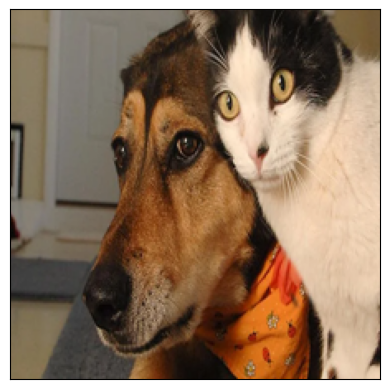

In [ ]:
normalizer = Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
torch_img = torch.from_numpy(np.asarray(pil_img)).permute(2, 0, 1).unsqueeze(0).float().div(255).cuda()
torch_img = F.interpolate(torch_img, size=(224, 224), mode='bilinear', align_corners=False) # (1, 3, 224, 224)
normed_torch_img = normalizer(torch_img) # (1, 3, 224, 224)
img = np.transpose(torch_img.cpu().numpy().squeeze(), (1, 2, 0)) # (224, 224, 3)
plt.imshow(img)
ax = plt.gca()
ax.axes.xaxis.set_visible(False)
ax.axes.yaxis.set_visible(False)
plt.show()

In [ ]:
# normalizer = Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
# torch_img = torch.from_numpy(np.asarray(pil_img)).permute(2, 0, 1).unsqueeze(0).float().div(255).cuda()
# torch_img = F.interpolate(torch_img, size=(224, 224), mode='bilinear', align_corners=False) # (1, 3, 224, 224)
# normed_torch_img = normalizer(torch_img) # (1, 3, 224, 224)

In [ ]:
current_time = datetime.datetime.now() + datetime.timedelta(hours= 9)
current_time = current_time.strftime('%Y-%m-%d-%H:%M')

saved_loc = os.path.join('./', current_time)
if os.path.exists(saved_loc):
    shutil.rmtree(saved_loc)
os.mkdir(saved_loc)

print("결과 저장 위치: ", saved_loc)

결과 저장 위치:  ./2023-09-17-16:52


In [ ]:
from torch.autograd import Function


class GuidedBackpropReLU(Function):
    @staticmethod
    def forward(self, input_img):
        # input image 기준으로 양수인 부분만 1로 만드는 positive_mask 생성
        positive_mask = (input_img > 0).type_as(input_img)

        # torch.addcmul(input, tensor1, tensor2) => output = input + tensor1 x tensor 2
        # input image와 동일한 사이즈의 torch.zeros를 만든 뒤, input image와 positive_mask를 곱해서 output 생성
        output = torch.addcmul(torch.zeros(input_img.size()).type_as(input_img), input_img, positive_mask)

        # backward에서 사용될 forward의 input이나 output을 저장
        self.save_for_backward(input_img, output)
        return output

    @staticmethod
    def backward(self, grad_output):

        # forward에서 저장된 saved tensor를 불러오기
        input_img, output = self.saved_tensors
        grad_input = None

        # input image 기준으로 양수인 부분만 1로 만드는 positive_mask 생성
        positive_mask_1 = (input_img > 0).type_as(grad_output)

        # 모델의 결과가 양수인 부분만 1로 만드는 positive_mask 생성
        positive_mask_2 = (grad_output > 0).type_as(grad_output)

        # 먼저 모델의 결과와 positive_mask_1과 곱해주고,
        # 다음으로는 positive_mask_2와 곱해줘서
        # 모델의 결과가 양수이면서 input image가 양수인 부분만 남도록 만들어줌
        grad_input = torch.addcmul(torch.zeros(input_img.size()).type_as(input_img),
                                   torch.addcmul(torch.zeros(input_img.size()).type_as(input_img), grad_output,
                                                 positive_mask_1), positive_mask_2)
        return grad_input

class GuidedBackpropReLUModel:
    def __init__(self, model, use_cuda):
        self.model = model
        self.model.eval()
        self.cuda = use_cuda
        if self.cuda:
            self.model = model.cuda()

        def recursive_relu_apply(module_top):
            for idx, module in module_top._modules.items():
                recursive_relu_apply(module)
                if module.__class__.__name__ == 'ReLU':
                    module_top._modules[idx] = GuidedBackpropReLU.apply

        # replace ReLU with GuidedBackpropReLU
        recursive_relu_apply(self.model)

    def forward(self, input_img):
        return self.model(input_img)

    def __call__(self, input_img, target_category=None):
        if self.cuda:
            input_img = input_img.cuda()

        input_img = input_img.requires_grad_(True)

        output = self.forward(input_img)

        if target_category is None:
            target_category = np.argmax(output.cpu().data.numpy())

        one_hot = np.zeros((1, output.size()[-1]), dtype=np.float32)
        one_hot[0][target_category] = 1
        one_hot = torch.from_numpy(one_hot).requires_grad_(True)
        if self.cuda:
            one_hot = one_hot.cuda()

        one_hot = torch.sum(one_hot * output)
        # 모델이 예측한 결과값을 기준으로 backward 진행
        one_hot.backward(retain_graph=True)

        # input image의 gradient를 저장
        output = input_img.grad.cpu().data.numpy()
        output = output[0, :, :, :]
        output = output.transpose((1, 2, 0))
        return output

In [ ]:
def deprocess_image(img):
    """ see https://github.com/jacobgil/keras-grad-cam/blob/master/grad-cam.py#L65 """
    img = img - np.mean(img)
    img = img / (np.std(img) + 1e-5)
    img = img * 0.1
    img = img + 0.5
    img = np.clip(img, 0, 1)
    return np.uint8(img * 255)

In [ ]:
# final conv layer name
finalconv_name = 'layer4'

# activations
feature_blobs = []

# gradients
backward_feature = []

# output으로 나오는 feature를 feature_blobs에 append하도록
def hook_feature(module, input, output):
    feature_blobs.append(output.cpu().data)


# Grad-CAM
def backward_hook(module, input, output):
    backward_feature.append(output[0])


resnet50._modules.get(finalconv_name).register_forward_hook(hook_feature)
resnet50._modules.get(finalconv_name).register_backward_hook(backward_hook)


# get the softmax weight
params = list(resnet50.parameters())
weight_softmax = np.squeeze(params[-2].cpu().detach().numpy()) # [1000, 512]

# Prediction
logit = resnet50(normed_torch_img)
h_x = F.softmax(logit, dim=1).data.squeeze() # softmax 적용




In [ ]:

# ============================= #
# ==== Grad-CAM main lines ==== #
# ============================= #


# Tabby Cat: 281, pug-dog: 227  227 281
score = logit[:, 227].squeeze() # 예측값 y^c
score.backward(retain_graph = True) # 예측값 y^c에 대해서 backprop 진행

activations = feature_blobs[0].to(device) # (1, 512, 7, 7), forward activations
gradients = backward_feature[0] # (1, 512, 7, 7), backward gradients
b, k, u, v = gradients.size()

alpha = gradients.view(b, k, -1).mean(2) # (1, 512, 7*7) => (1, 512), feature map k의 'importance'
weights = alpha.view(b, k, 1, 1) # (1, 512, 1, 1)

grad_cam_map = (weights*activations).sum(1, keepdim = True) # alpha * A^k = (1, 512, 7, 7) => (1, 1, 7, 7)
grad_cam_map = F.relu(grad_cam_map) # Apply R e L U
grad_cam_map = F.interpolate(grad_cam_map, size=(224, 224), mode='bilinear', align_corners=False) # (1, 1, 224, 224)
map_min, map_max = grad_cam_map.min(), grad_cam_map.max()
grad_cam_map = (grad_cam_map - map_min).div(map_max - map_min).data # (1, 1, 224, 224), min-max scaling

# grad_cam_map.squeeze() : (224, 224)
grad_heatmap = cv2.applyColorMap(np.uint8(255 * grad_cam_map.squeeze().cpu()), cv2.COLORMAP_JET) # (224, 224, 3), numpy

# Grad-CAM heatmap save
cv2.imwrite(os.path.join(saved_loc, "Grad_CAM_heatmap.jpg"), grad_heatmap)

grad_heatmap = np.float32(grad_heatmap) / 255

grad_result = grad_heatmap + img
grad_result = grad_result / np.max(grad_result)
grad_result = np.uint8(255 * grad_result)

# Grad-CAM Result save
cv2.imwrite(os.path.join(saved_loc, "Grad_Result.jpg"), grad_result)


# ============================= #
# ==Guided-Backprop main lines= #
# ============================= #

# gb_model => ReLU function in resnet50 change to GuidedBackpropReLU.
gb_model = GuidedBackpropReLUModel(model=resnet50, use_cuda=True)
gb_num = gb_model(torch_img, target_category = 254)
gb = deprocess_image(gb_num) # (224, 224, 3), numpy

# Guided Backprop save
cv2.imwrite(os.path.join(saved_loc, "Guided_Backprop.jpg"), gb)


# Guided-Backpropagation * Grad-CAM => Guided Grad-CAM
# See Fig. 2 in paper.
# grad_cam_map : (1, 1, 224, 224) , torch.Tensor
grayscale_cam = grad_cam_map.squeeze(0).cpu().numpy() # (1, 224, 224), numpy
grayscale_cam = grayscale_cam[0, :] # (224, 224)
cam_mask = cv2.merge([grayscale_cam, grayscale_cam, grayscale_cam]) # (224, 224, 3)

cam_gb = deprocess_image(cam_mask * gb_num)

# Guided Grad-CAM save
cv2.imwrite(os.path.join(saved_loc, "Guided_Grad_CAM.jpg"), cam_gb)

True

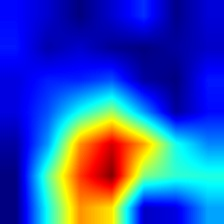

In [ ]:
# Show Grad-CAM heatmap
PIL.Image.open(os.path.join(saved_loc, "Grad_CAM_heatmap.jpg"))

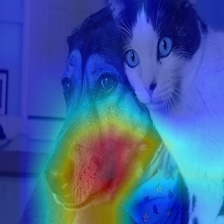

In [ ]:
# Show Grad-CAM Result
PIL.Image.open(os.path.join(saved_loc, "Grad_Result.jpg"))

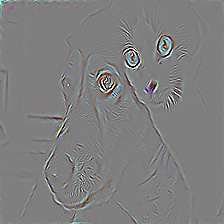

In [ ]:
# Show Guided-Backpropagation
PIL.Image.open(os.path.join(saved_loc, "Guided_Backprop.jpg"))


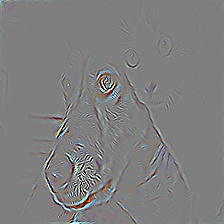

In [ ]:
# Show Guided Grad-CAM
PIL.Image.open(os.path.join(saved_loc, "Guided_Grad_CAM.jpg"))

# LayerCAM using torchCAM

레이어별로 보는바가 다르다!

![](https://d3i71xaburhd42.cloudfront.net/bfd6684c309dc8d560522017d44da0d6d4ee0359/4-Figure4-1.png)

![](http://iislab.skku.edu/iish/files/attach/images/1210/974/053/99b983892094b5c6d2fc3736e15da7d1.png)

In [4]:
!pip install torchcam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 887.5/887.5 MB 2.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 64.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 557.1/557.1 MB 3.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 317.1/317.1 MB 4.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.0/21.0 MB 68.1 MB/s eta 0:00:00
  Attempting uninstall: torch
    Found existing installation: torch 2.0.1+cu118
    Uninstalling torch-2.0.1+cu118:
      Successfully uninstalled torch-2.0.1+cu118
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchaudio 2.0.2+cu118 requires torch==2.0.1, but you have torch 1.13.1 which is incompatible.
torchdata 0.6.1 requires torch==2.0.1, but you have torch 1.13.1 which is incompatible.
torchtext 0.15.2 requires torch==2.0.1, but you have torch 1.13.1 which

## From source

In [ ]:
# # Install the most up-to-date version from GitHub
# !pip install -e git+https://github.com/frgfm/torch-cam.git#egg=torchcam

Now go to `Runtime/Restart runtime` for your changes to take effect!

## Basic usage

In [5]:
%matplotlib inline
# All imports
import matplotlib.pyplot as plt
import torch
from torch.nn.functional import softmax, interpolate
from torchvision.io.image import read_image
from torchvision.models import resnet18
from torchvision.transforms.functional import normalize, resize, to_pil_image

from torchcam.methods import SmoothGradCAMpp, LayerCAM
from torchcam.utils import overlay_mask

In [6]:
# Download an image
!wget https://www.woopets.fr/assets/races/000/066/big-portrait/border-collie.jpg
# Set this to your image path if you wish to run it on your own data
img_path = "border-collie.jpg"

--2023-09-18 07:26:47--  https://www.woopets.fr/assets/races/000/066/big-portrait/border-collie.jpg
Resolving www.woopets.fr (www.woopets.fr)... 104.26.12.50, 172.67.73.8, 104.26.13.50, ...
Connecting to www.woopets.fr (www.woopets.fr)|104.26.12.50|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 273044 (267K) [image/jpeg]
Saving to: ‘border-collie.jpg.1’

border-collie.jpg.1 100%[===================>] 266.64K  --.-KB/s    in 0.02s   

2023-09-18 07:26:47 (17.1 MB/s) - ‘border-collie.jpg.1’ saved [273044/273044]



In [12]:
# Instantiate your model here
model = resnet18(pretrained=True).eval()

/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [13]:
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

## Illustrate your classifier capabilities

In [14]:
cam_extractor = SmoothGradCAMpp(model)
# Get your input
img = read_image(img_path)
# Preprocess it for your chosen model
input_tensor = normalize(resize(img, (224, 224)) / 255., [0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

# Preprocess your data and feed it to the model
out = model(input_tensor.unsqueeze(0))
# Retrieve the CAM by passing the class index and the model output
idx = out.squeeze(0).argmax().item()
print("id:",idx)
cams = cam_extractor(idx, out)

/usr/local/lib/python3.10/dist-packages/torchvision/transforms/functional.py:1603: UserWarning: The default value of the antialias parameter of all the resizing transforms (Resize(), RandomResizedCrop(), etc.) will change from None to True in v0.17, in order to be consistent across the PIL and Tensor backends. To suppress this warning, directly pass antialias=True (recommended, future default), antialias=None (current default, which means False for Tensors and True for PIL), or antialias=False (only works on Tensors - PIL will still use antialiasing). This also applies if you are using the inference transforms from the models weights: update the call to weights.transforms(antialias=True).
  warnings.warn(


id: 232


In [15]:
# Notice that there is one CAM per target layer (here only 1)
for cam in cams:
  print(cam.shape)

torch.Size([1, 7, 7])


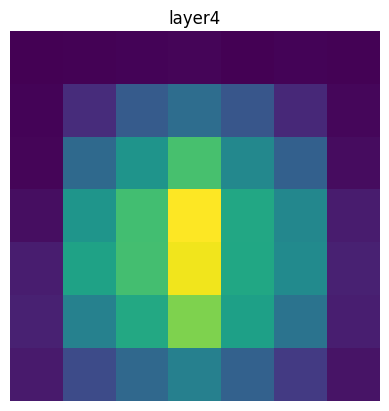

In [16]:
# The raw CAM
for name, cam in zip(cam_extractor.target_names, cams):
  plt.imshow(cam.squeeze(0).numpy())
  plt.axis('off')
  plt.title(name)
  plt.show()

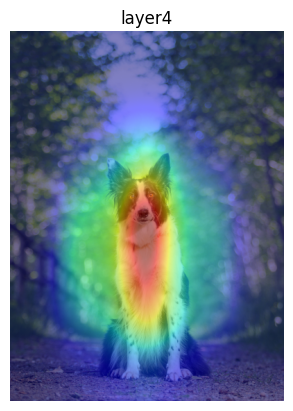

In [17]:
# Overlayed on the image
for name, cam in zip(cam_extractor.target_names, cams):
  result = overlay_mask(to_pil_image(img), to_pil_image(cam.squeeze(0), mode='F'), alpha=0.5)
  plt.imshow(result); plt.axis('off'); plt.title(name); plt.show()

In [18]:
# Once you're finished, clear the hooks on your model
cam_extractor.remove_hooks()

## Extract localization cues

In [19]:
# Retrieve the CAM from several layers at the same time
cam_extractor = LayerCAM(model)

# Preprocess your data and feed it to the model
out = model(input_tensor.unsqueeze(0))
print(softmax(out, dim=1).max())

tensor(0.9115, grad_fn=<MaxBackward1>)


In [20]:
cams = cam_extractor(out.squeeze(0).argmax().item(), out)

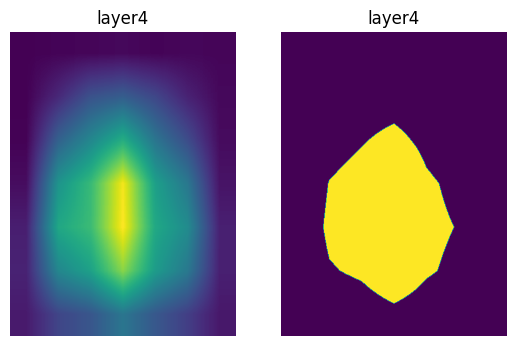

In [21]:
# Resize it
resized_cams = [resize(to_pil_image(cam.squeeze(0)), img.shape[-2:]) for cam in cams]
segmaps = [to_pil_image((resize(cam, img.shape[-2:]).squeeze(0) >= 0.5).to(dtype=torch.float32)) for cam in cams]

# Plot it
for name, cam, seg in zip(cam_extractor.target_names, resized_cams, segmaps):
  _, axes = plt.subplots(1, 2)
  axes[0].imshow(cam)
  axes[0].axis('off')
  axes[0].set_title(name)
  axes[1].imshow(seg)
  axes[1].axis('off')
  axes[1].set_title(name)
  plt.show()

In [22]:
# Once you're finished, clear the hooks on your model
cam_extractor.remove_hooks()

## Fuse CAMs from multiple layers

In [29]:
#torchvision.models.efficientnet_b0
# Instantiate your model here
from torchvision.models import efficientnet_b0
model = efficientnet_b0(pretrained=True).eval()

/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-3dd342df.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-3dd342df.pth
100%|██████████| 20.5M/20.5M [00:00<00:00, 166MB/s]


In [45]:
for name, module in model.named_modules():  #named_modules() 이거임!!!!!! ㅋㅋㅋ
    print(name)


features
features.0
features.0.0
features.0.1
features.0.2
features.1
features.1.0
features.1.0.block
features.1.0.block.0
features.1.0.block.0.0
features.1.0.block.0.1
features.1.0.block.0.2
features.1.0.block.1
features.1.0.block.1.avgpool
features.1.0.block.1.fc1
features.1.0.block.1.fc2
features.1.0.block.1.activation
features.1.0.block.1.scale_activation
features.1.0.block.2
features.1.0.block.2.0
features.1.0.block.2.1
features.1.0.stochastic_depth
features.2
features.2.0
features.2.0.block
features.2.0.block.0
features.2.0.block.0.0
features.2.0.block.0.1
features.2.0.block.0.2
features.2.0.block.1
features.2.0.block.1.0
features.2.0.block.1.1
features.2.0.block.1.2
features.2.0.block.2
features.2.0.block.2.avgpool
features.2.0.block.2.fc1
features.2.0.block.2.fc2
features.2.0.block.2.activation
features.2.0.block.2.scale_activation
features.2.0.block.3
features.2.0.block.3.0
features.2.0.block.3.1
features.2.0.stochastic_depth
features.2.1
features.2.1.block
features.2.1.block

In [51]:
# Retrieve the CAM from several layers at the same time
cam_extractor = LayerCAM(model, ["features.8","features.5","features.3","features.1"])

# Preprocess your data and feed it to the model
out = model(input_tensor.unsqueeze(0))
# Retrieve the CAM by passing the class index and the model output
cams = cam_extractor(out.squeeze(0).argmax().item(), out)

In [52]:
# This time, there are several CAMs
for cam in cams:
  print(cam.shape)

torch.Size([1, 7, 7])
torch.Size([1, 14, 14])
torch.Size([1, 28, 28])
torch.Size([1, 112, 112])


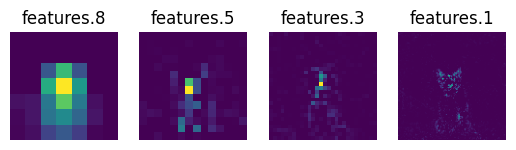

In [53]:
# The raw CAM
_, axes = plt.subplots(1, len(cam_extractor.target_names))
for idx, name, cam in zip(range(len(cam_extractor.target_names)), cam_extractor.target_names, cams):
  axes[idx].imshow(cam.squeeze(0).numpy()); axes[idx].axis('off'); axes[idx].set_title(name);
plt.show()

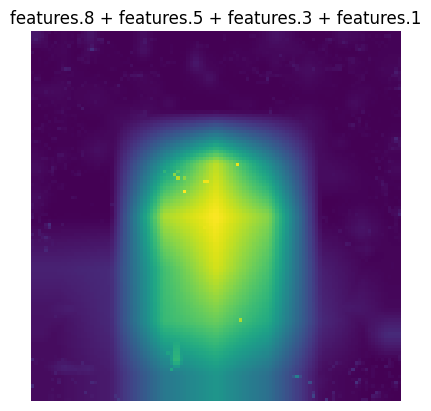

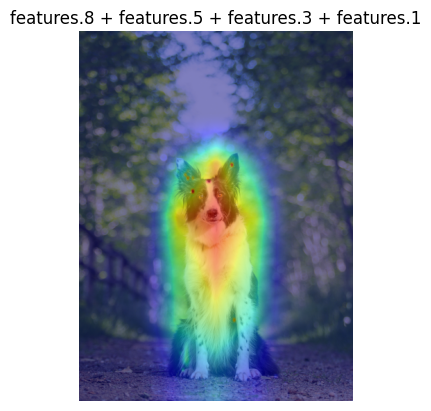

In [54]:
# Let's fuse them
fused_cam = cam_extractor.fuse_cams(cams)
# Plot the raw version
plt.imshow(fused_cam.squeeze(0).numpy()); plt.axis('off'); plt.title(" + ".join(cam_extractor.target_names)); plt.show()
# Plot the overlayed version
result = overlay_mask(to_pil_image(img), to_pil_image(fused_cam, mode='F'), alpha=0.5)
plt.imshow(result); plt.axis('off'); plt.title(" + ".join(cam_extractor.target_names)); plt.show()

In [44]:
# Once you're finished, clear the hooks on your model
cam_extractor.remove_hooks()


# TorchScript

>ref: https://tutorials.pytorch.kr/beginner/Intro_to_TorchScript_tutorial.html


![](https://i0.wp.com/blog.dramancompany.com/wp-content/uploads/2022/11/%E1%84%80%E1%85%B3%E1%84%85%E1%85%B5%E1%86%B7-1.-TorchScript%E1%84%8B%E1%85%B4-Script-Mode-%E1%84%87%E1%85%A7%E1%86%AB%E1%84%92%E1%85%AA%E1%86%AB.png?resize=2000%2C871&ssl=1)



Eager Mode (normal python runtime mode):  
> prototyping, training, experimenting을 위해 파이썬의 특징을 최대한 사용함


산업에서 사용하기 위해서는
1. 다양한 환경에서 동작가능해야함 (다양한 환경에서)
2. 동작 성능이 좋아져야 함. (가볍고 빠르게)

Script Mode
> production deployment를 위해 변환한 모드
runtime 과정에서 Python Interpreter로 실행되지 않기 때문에 병렬 연산, 최적화 등이 가능해진다.


## Eager To Script Mode 1: torch.jit.trace()

Tracing 방법은 어떤 입력값(data instance)을 사용하여 모델의 구조를 파악하고, 이 입력값의 모델 안에서의 흐름을 통해 모델을 기록하는 방식임.
> 조건문을 많이 사용하지 않는 모델의 경우 이 방식을 이용하여 변환하는 것이 적합하다.




In [1]:
import torch  # This is all you need to use both PyTorch and TorchScript!
import torch.nn as nn
print(torch.__version__)

2.0.1+cu118


간다한 모델 하나를 정의해보자

In [2]:
class MyDecisionGate(nn.Module):
    def forward(self, x):
        if x.sum() > 0:
            return x
        else:
            return -x

class MyCell(nn.Module):
    def __init__(self):
        super().__init__()
        self.dg = MyDecisionGate()
        self.linear = nn.Linear(4, 4)

    def forward(self, x, h):
        new_h = torch.tanh(self.dg(self.linear(x)) + h)
        return new_h, new_h

my_cell = MyCell()
x, h = torch.rand(3, 4), torch.rand(3, 4)
print(my_cell)
print(my_cell(x, h))

MyCell(
  (dg): MyDecisionGate()
  (linear): Linear(in_features=4, out_features=4, bias=True)
)
(tensor([[ 0.7898,  0.8490,  0.5900,  0.7530],
        [ 0.9195, -0.1289,  0.4297, -0.2702],
        [ 0.8082,  0.6280,  0.0364, -0.0477]], grad_fn=<TanhBackward0>), tensor([[ 0.7898,  0.8490,  0.5900,  0.7530],
        [ 0.9195, -0.1289,  0.4297, -0.2702],
        [ 0.8082,  0.6280,  0.0364, -0.0477]], grad_fn=<TanhBackward0>))


TorchScript는 PyTorch의 유연하고 동적인 특성을 고려하여 모델 정의를 캡쳐할 수 있는
**추적(tracing)** 을 제공함.

 ``Module`` 추적




In [3]:
class MyCell(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(4, 4)

    def forward(self, x, h):
        new_h = torch.tanh(self.linear(x) + h)
        return new_h, new_h

my_cell = MyCell()
x, h = torch.rand(3, 4), torch.rand(3, 4)
traced_cell = torch.jit.trace(my_cell, (x, h))  # 구조와 입력 예시를 전달
print(traced_cell)
traced_cell(x, h)

MyCell(
  original_name=MyCell
  (linear): Linear(original_name=Linear)
)


(tensor([[ 0.8781,  0.6566, -0.1471,  0.3022],
         [ 0.7569,  0.7009, -0.0198,  0.8152],
         [ 0.9209,  0.6561,  0.5287,  0.3302]], grad_fn=<TanhBackward0>),
 tensor([[ 0.8781,  0.6566, -0.1471,  0.3022],
         [ 0.7569,  0.7009, -0.0198,  0.8152],
         [ 0.9209,  0.6561,  0.5287,  0.3302]], grad_fn=<TanhBackward0>))

이전에 이것을 인스턴스화 했지만 이번엔 ``torch.jit.trace`` 를 호출하고, ``Module`` 을
전달했으며, 네트워크가 볼 수 있는 *입력 예* 를 전달했습니다.

여기서 무슨 일이 발생했습니까? ``Module`` 을 호출하였고, ``Module`` 이 돌아갈 때
발생한 연산을 기록하였고, ``torch.jit.ScriptModule`` 의 인스터스를 생성했습니다.
( ``TracedModule`` 은 인스턴스입니다)






## TorchScript:``.graph`` , ``.code``

1. .graph: 저수준 그래프 표현
2. .code: 파이썬 구문에 대한 해석 기록

In [4]:
print(traced_cell.graph)

graph(%self.1 : __torch__.MyCell,
      %x : Float(3, 4, strides=[4, 1], requires_grad=0, device=cpu),
      %h : Float(3, 4, strides=[4, 1], requires_grad=0, device=cpu)):
  %linear : __torch__.torch.nn.modules.linear.Linear = prim::GetAttr[name="linear"](%self.1)
  %20 : Tensor = prim::CallMethod[name="forward"](%linear, %x)
  %11 : int = prim::Constant[value=1]() # <ipython-input-3-123e411f37e7>:7:0
  %12 : Float(3, 4, strides=[4, 1], requires_grad=1, device=cpu) = aten::add(%20, %h, %11) # <ipython-input-3-123e411f37e7>:7:0
  %13 : Float(3, 4, strides=[4, 1], requires_grad=1, device=cpu) = aten::tanh(%12) # <ipython-input-3-123e411f37e7>:7:0
  %14 : (Float(3, 4, strides=[4, 1], requires_grad=1, device=cpu), Float(3, 4, strides=[4, 1], requires_grad=1, device=cpu)) = prim::TupleConstruct(%13, %13)
  return (%14)



In [5]:
print(traced_cell.code)

def forward(self,
    x: Tensor,
    h: Tensor) -> Tuple[Tensor, Tensor]:
  linear = self.linear
  _0 = torch.tanh(torch.add((linear).forward(x, ), h))
  return (_0, _0)



**어째서** 이런 일들을 했을까요? 여기에는 몇 가지 이유가 있습니다:

1. TorchScript 코드는 자체 인터프리터에서
   호출될 수 있습니다. 이 인터프리터는 파이썬의 GIL(Global Interpreter Lock)을 얻지
   않으므로 동일한 인스턴스에서 동시에 많은 요청을 처리할 수 있습니다.
2. 이는 전체 모델을 저장하고 Python 이외에도 다른 언어로 작성된 서버와 같은 다른 환경에서도 동작함.
3. TorchScript는 보다 효율적인 실행을 제공하기 위해 코드에서 컴파일러 최적화를 수행할 수 있는 표현을 제공.


``traced_cell`` 을 호출하면 Python 모듈과 동일한 결과가 생성됩니다:




In [13]:
print(my_cell(x, h))
print(traced_cell(x, h))

(tensor([[ 0.8781,  0.6566, -0.1471,  0.3022],
        [ 0.7569,  0.7009, -0.0198,  0.8152],
        [ 0.9209,  0.6561,  0.5287,  0.3302]], grad_fn=<TanhBackward0>), tensor([[ 0.8781,  0.6566, -0.1471,  0.3022],
        [ 0.7569,  0.7009, -0.0198,  0.8152],
        [ 0.9209,  0.6561,  0.5287,  0.3302]], grad_fn=<TanhBackward0>))
(tensor([[ 0.8781,  0.6566, -0.1471,  0.3022],
        [ 0.7569,  0.7009, -0.0198,  0.8152],
        [ 0.9209,  0.6561,  0.5287,  0.3302]],
       grad_fn=<DifferentiableGraphBackward>), tensor([[ 0.8781,  0.6566, -0.1471,  0.3022],
        [ 0.7569,  0.7009, -0.0198,  0.8152],
        [ 0.9209,  0.6561,  0.5287,  0.3302]],
       grad_fn=<DifferentiableGraphBackward>))


Tracing 방식은 eager model의 코드를 재사용할 수 있는 효과적인 방법임.



***Important!***
> 그러나 이 방식을 사용하면 Control-flow나 data structure, python construct가 보존되지 않는다. 따라서 이 방식을 사용하는 경우에는 항상 IR을 검사하여 pytorch model이 올바르게 동작하는지를 확인해줘야한다.


---
아래 예시 확인

In [14]:
class MyDecisionGate(torch.nn.Module):
    def forward(self, x):
        if x.sum() > 0:
            return x
        else:
            return -x

class MyCell(torch.nn.Module):
    def __init__(self, dg):
        super().__init__()
        self.dg = dg
        self.linear = torch.nn.Linear(4, 4)

    def forward(self, x, h):
        new_h = torch.tanh(self.dg(self.linear(x)) + h)
        return new_h, new_h

my_cell = MyCell(MyDecisionGate())
traced_cell = torch.jit.trace(my_cell, (x, h))

print(traced_cell.dg.code)
print(traced_cell.code)

def forward(self,
    argument_1: Tensor) -> NoneType:
  return None

def forward(self,
    x: Tensor,
    h: Tensor) -> Tuple[Tensor, Tensor]:
  dg = self.dg
  linear = self.linear
  _0 = (linear).forward(x, )
  _1 = (dg).forward(_0, )
  _2 = torch.tanh(torch.add(_0, h))
  return (_2, _2)



<ipython-input-14-39d31217401e>:3: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if x.sum() > 0:




```
def forward(self,
    argument_1: Tensor) -> NoneType:
  return None
```

어?!... 어디갔죠? 함수 MyDecisionGate 내용물이 사라졌습니다!

파이썬의 기능을 활용하는 부분을 부분을 제거해버린것.


이러한 limitation을 해결하기 위해 Annotation 방식이 고안되었다.





## Eager To Script Mode 2: torch.jit.script()

제어 흐름이 포함된(control-flow-laden) 경우 모듈 버전 2를 사용하는 방법.

TorchScript에서 이 모듈을 어떻게 충실하게 나타낼 수 있을까요? Python 소스 코드를
직접 분석하여 TorchScript로 변환하는 **스크립트 컴파일러(script compiler)** 를
제공합니다. ``MyDecisionGate`` 를 스크립트 컴파일러를 사용하여 변환해 봅시다:




In [17]:
scripted_gate = torch.jit.script(MyDecisionGate())

my_cell = MyCell(scripted_gate)
scripted_cell = torch.jit.script(my_cell)

print(scripted_gate.code)
print(scripted_cell.code)

def forward(self,
    x: Tensor) -> Tensor:
  if bool(torch.gt(torch.sum(x), 0)):
    _0 = x
  else:
    _0 = torch.neg(x)
  return _0

def forward(self,
    x: Tensor,
    h: Tensor) -> Tuple[Tensor, Tensor]:
  dg = self.dg
  linear = self.linear
  _0 = torch.add((dg).forward((linear).forward(x, ), ), h)
  new_h = torch.tanh(_0)
  return (new_h, new_h)



만세! 이제 TorchScript에서 프로그램의 동작을 충실하게 캡쳐했습니다. 이제
프로그램을 실행해 봅시다:




In [18]:
# 새로운 입력
x, h = torch.rand(3, 4), torch.rand(3, 4)
traced_cell(x, h)

(tensor([[0.7248, 0.7864, 0.6878, 0.9346],
         [0.7567, 0.8915, 0.5038, 0.7516],
         [0.8729, 0.2309, 0.6688, 0.7903]], grad_fn=<TanhBackward0>),
 tensor([[0.7248, 0.7864, 0.6878, 0.9346],
         [0.7567, 0.8915, 0.5038, 0.7516],
         [0.8729, 0.2309, 0.6688, 0.7903]], grad_fn=<TanhBackward0>))

### 스크립팅과 추적 혼합

어떤 상황에서는 스크립팅보다는 추적을 사용해야 합니다. (예: 모듈에는 TorchScript에
표시하지 않으려는 Python 상수 값을 기반으로 만들어진 많은 구조적인
결정(architectural decisions)이 있습니다.) 이 경우, 스크립팅은 추적으로
구성될 수 있습니다: ``torch.jit.script`` 는 추적된 모듈의 코드를 인라인(inline)
할 것이고, 추적은 스크립트 된 모듈의 코드를 인라인 할 것입니다.

첫 번째 경우의 예:




In [19]:
class MyRNNLoop(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.cell = torch.jit.trace(MyCell(scripted_gate), (x, h))

    def forward(self, xs):
        h, y = torch.zeros(3, 4), torch.zeros(3, 4)
        for i in range(xs.size(0)):
            y, h = self.cell(xs[i], h)
        return y, h

rnn_loop = torch.jit.script(MyRNNLoop())
print(rnn_loop.code)

def forward(self,
    xs: Tensor) -> Tuple[Tensor, Tensor]:
  h = torch.zeros([3, 4])
  y = torch.zeros([3, 4])
  y0 = y
  h0 = h
  for i in range(torch.size(xs, 0)):
    cell = self.cell
    _0 = (cell).forward(torch.select(xs, 0, i), h0, )
    y1, h1, = _0
    y0, h0 = y1, h1
  return (y0, h0)



두 번째 경우의 예:




In [20]:
class WrapRNN(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.loop = torch.jit.script(MyRNNLoop())

    def forward(self, xs):
        y, h = self.loop(xs)
        return torch.relu(y)

traced = torch.jit.trace(WrapRNN(), (torch.rand(10, 3, 4)))
print(traced.code)

def forward(self,
    xs: Tensor) -> Tensor:
  loop = self.loop
  _0, y, = (loop).forward(xs, )
  return torch.relu(y)



이러한 방식으로, 스크립팅과 추적은 상황에 따라서 따로 사용되거나, 함께
사용될 수 있습니다.

## 모델 저장 및 불러오기

TorchScript 모듈을 아카이브 형식으로 디스크에 저장하고 불러오는 API를 제공합니다.
이 형식은 코드, 매개 변수, 속성과 디버그 정보를 포함합니다. 이것은 그 아카이브가
완전히 별개의 프로세스로 로드할 수 있는 모델의 독립 표현임을 의미합니다.
랩핑 된 RNN 모듈을 저장하고 로드해 봅시다:




In [21]:
traced.save('wrapped_rnn.pt')

loaded = torch.jit.load('wrapped_rnn.pt')

print(loaded)
print(loaded.code)

RecursiveScriptModule(
  original_name=WrapRNN
  (loop): RecursiveScriptModule(
    original_name=MyRNNLoop
    (cell): RecursiveScriptModule(
      original_name=MyCell
      (dg): RecursiveScriptModule(original_name=MyDecisionGate)
      (linear): RecursiveScriptModule(original_name=Linear)
    )
  )
)
def forward(self,
    xs: Tensor) -> Tensor:
  loop = self.loop
  _0, y, = (loop).forward(xs, )
  return torch.relu(y)



In [22]:
import torch
import torch.nn.functional as F
import torchvision.models as models

r18 = models.resnet18(pretrained=True)       # 이제 사전 학습된 모델의 인스턴스가 있습니다.
r18_scripted = torch.jit.script(r18)         # *** 여기가 TorchScript로 내보내는 부분입니다.
dummy_input = torch.rand(1, 3, 224, 224)     # 빠르게 테스트 해봅니다.

/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


정말 두 모델이 같은지 확인 해보자

In [23]:
unscripted_output = r18(dummy_input)         # 스크립트화 되지 않은 모델의 예측을 얻고...
scripted_output = r18_scripted(dummy_input)  # ...스크립트화 된 모델도 똑같이 반복합니다.

unscripted_top5 = F.softmax(unscripted_output, dim=1).topk(5).indices
scripted_top5 = F.softmax(scripted_output, dim=1).topk(5).indices

print('Python model top 5 results:\n  {}'.format(unscripted_top5))
print('TorchScript model top 5 results:\n  {}'.format(scripted_top5))

Python model top 5 results:
  tensor([[463, 600, 412, 731, 898]])
TorchScript model top 5 results:
  tensor([[463, 600, 412, 731, 898]])


In [24]:
r18_scripted.save('r18_scripted.pt')

## 다른 예제

In [25]:
import torchvision
import torch
from time import perf_counter
import numpy as np

def timer(f,*args):
    start = perf_counter()
    f(*args)
    return (1000 * (perf_counter() - start))

# Example 1.1 Pytorch cpu version
model_ft = torchvision.models.resnet18(pretrained=True)
model_ft.eval()
x_ft = torch.rand(1,3, 224,224)
print("normal cpu eval mode: ", np.mean([timer(model_ft,x_ft) for _ in range(10)]))

# Example 1.2 Pytorch gpu version
model_ft_gpu = torchvision.models.resnet18(pretrained=True).cuda()
x_ft_gpu = x_ft.cuda()
model_ft_gpu.eval()
print("normal gpu eval mode: ", np.mean([timer(model_ft_gpu,x_ft_gpu) for _ in range(10)]))

# Example 2.1 torch.jit.script cpu version
script_cell = torch.jit.script(model_ft, (x_ft))
print("torch.jit.script cpu: ", np.mean([timer(script_cell,x_ft) for _ in range(10)]))

# Example 2.2 torch.jit.script gpu version
script_cell_gpu = torch.jit.script(model_ft_gpu, (x_ft_gpu))
print("torch.jit.script GPU: ",np.mean([timer(script_cell_gpu,x_ft.cuda()) for _ in range(100)]))

normal cpu eval mode:  120.209014799957
normal gpu eval mode:  2.7652652999222482


/usr/local/lib/python3.10/dist-packages/torch/jit/_script.py:1241: UserWarning: `optimize` is deprecated and has no effect. Use `with torch.jit.optimized_execution() instead
  warnings.warn(


torch.jit.script cpu:  77.25289009995322
torch.jit.script GPU:  1.583232670009238


훨씬 빠르죠?!

# ONNX

![](https://learn.microsoft.com/ko-kr/azure/machine-learning/media/concept-onnx/onnx.png?view=azureml-api-2)
> 통일!


## PyTorch 모델을 ONNX으로 변환하고 ONNX 런타임에서 실행하기

> ONNX 런타임은 ONNX 모델을 위한 엔진으로서 성능에 초점을 맞추고 있고 여러 다양한 플랫폼과 하드웨어(윈도우,
리눅스, 맥을 비롯한 플랫폼 뿐만 아니라 CPU, GPU 등의 하드웨어)에서 효율적인 추론을 가능하게 합니다.


In [26]:
!pip install onnx onnxruntime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.6/14.6 MB 33.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.9/5.9 MB 40.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 6.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.8/86.8 kB 10.6 MB/s eta 0:00:00


In [27]:
# 필요한 import문
import io
import numpy as np

from torch import nn
import torch.utils.model_zoo as model_zoo
import torch.onnx

초해상화(super-resolution) 예시
> 이미지나 비디오의 해상도를 높이기 위한 방법으로 이미지 프로세싱이나 비디오 편집에 널리 사용되고 있는 방법임.


> paper: "Real-Time Single Image and Video Super-Resolution Using an Efficient
Sub-Pixel Convolutional Neural Network" - Shi et al

먼저, 초해상화 모델을 PyTorch에서 구현하겠습니다.
> ref: https://arxiv.org/abs/1609.05158


> ref: https://github.com/pytorch/examples/blob/master/super_resolution/model.py


효율적인 서브픽셀 합성곱 계층을 사용하여 이미지의 해상도를 업스케일 인자만큼 늘립니다.
모델은 이미지의 YCbCr 성분 중 Y 성분을 입력값으로 받고 업스케일된 초해상도의 Y 채널 값을 리턴합니다.




In [29]:
# PyTorch에서 구현된 초해상도 모델
import torch.nn as nn
import torch.nn.init as init


class SuperResolutionNet(nn.Module):
    def __init__(self, upscale_factor, inplace=False):
        super().__init__()

        self.relu = nn.ReLU(inplace=inplace)
        self.conv1 = nn.Conv2d(1, 64, (5, 5), (1, 1), (2, 2))
        self.conv2 = nn.Conv2d(64, 64, (3, 3), (1, 1), (1, 1))
        self.conv3 = nn.Conv2d(64, 32, (3, 3), (1, 1), (1, 1))
        self.conv4 = nn.Conv2d(32, upscale_factor ** 2, (3, 3), (1, 1), (1, 1))
        self.pixel_shuffle = nn.PixelShuffle(upscale_factor)

        self._initialize_weights()

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))
        x = self.relu(self.conv3(x))
        x = self.pixel_shuffle(self.conv4(x))
        return x

    def _initialize_weights(self):
        init.orthogonal_(self.conv1.weight, init.calculate_gain('relu'))
        init.orthogonal_(self.conv2.weight, init.calculate_gain('relu'))
        init.orthogonal_(self.conv3.weight, init.calculate_gain('relu'))
        init.orthogonal_(self.conv4.weight)

# 위에서 정의된 모델을 사용하여 초해상도 모델 생성
torch_model = SuperResolutionNet(upscale_factor=3)

모델을 변환하기 전에 모델을 추론 모드로 바꾸기 위해서 ``torch_model.eval()`` 또는 ``torch_model.train(False)`` 를 호출하는 것이 중요합니다.
이는 dropout이나 batchnorm과 같은 연산들이 추론과 학습 모드에서 다르게 작동하기 때문에 필요합니다.




In [30]:
# 미리 학습된 가중치를 읽어옵니다
model_url = 'https://s3.amazonaws.com/pytorch/test_data/export/superres_epoch100-44c6958e.pth'
batch_size = 1    # 임의의 수

# 모델을 미리 학습된 가중치로 초기화합니다
map_location = lambda storage, loc: storage
if torch.cuda.is_available():
    map_location = None
torch_model.load_state_dict(model_zoo.load_url(model_url, map_location=map_location))

# 모델을 추론 모드로 전환합니다
torch_model.eval()

Downloading: "https://s3.amazonaws.com/pytorch/test_data/export/superres_epoch100-44c6958e.pth" to /root/.cache/torch/hub/checkpoints/superres_epoch100-44c6958e.pth
100%|██████████| 234k/234k [00:00<00:00, 2.80MB/s]


SuperResolutionNet(
  (relu): ReLU()
  (conv1): Conv2d(1, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(32, 9, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pixel_shuffle): PixelShuffle(upscale_factor=3)
)

이제 Tracing이나 스크립팅을 통해서 PyTorch 모델을 변환할 수 있습니다.
이 튜토리얼에서는 tracing을 통해 변환된 모델을 사용하도록 하겠습니다.


모델을 변환하기 위해서는 ``torch.onnx.export()`` 함수를 호출합니다.
이 함수는 모델을 실행하여 어떤 연산자들이 출력값을 계산하는데 사용되었는지를 기록합니다.
``export`` 함수가 모델을 실행하기 때문에, 우리가 직접 텐서를 입력값으로 넘겨주어야 합니다.
이 텐서의 값은 알맞은 자료형과 모양이라면 랜덤하게 결정되어도 무방합니다.
특정 차원을 동적 차원으로 지정하지 않는 이상, ONNX로 변환된 그래프의 경우 입력값의 크기는 모든 차원에 대해 고정됩니다.


예시에서는 모델이 항상 배치 사이즈 1을 사용하도록 변환하였지만, ``torch.onnx.export()`` 의 ``dynamic_axes`` 인자의
첫번째 차원은 동적 차원으로 지정합니다. 따라서 변환된 모델은 임의의 batch_size에 대해 [batch_size, 1, 224, 224] 사이즈
입력값을 받을 수 있습니다.





In [31]:
# 모델에 대한 입력값
x = torch.randn(batch_size, 1, 224, 224, requires_grad=True)
torch_out = torch_model(x)

# 모델 변환
torch.onnx.export(torch_model,               # 실행될 모델
                  x,                         # 모델 입력값 (튜플 또는 여러 입력값들도 가능)
                  "super_resolution.onnx",   # 모델 저장 경로 (파일 또는 파일과 유사한 객체 모두 가능)
                  export_params=True,        # 모델 파일 안에 학습된 모델 가중치를 저장할지의 여부
                  opset_version=10,          # 모델을 변환할 때 사용할 ONNX 버전
                  do_constant_folding=True,  # 최적화시 상수폴딩을 사용할지의 여부
                  input_names = ['input'],   # 모델의 입력값을 가리키는 이름
                  output_names = ['output'], # 모델의 출력값을 가리키는 이름
                  dynamic_axes={'input' : {0 : 'batch_size'},    # 가변적인 길이를 가진 차원
                                'output' : {0 : 'batch_size'}})

============= Diagnostic Run torch.onnx.export version 2.0.1+cu118 =============
verbose: False, log level: Level.ERROR
======================= 0 NONE 0 NOTE 0 WARNING 0 ERROR ========================



ONNX 런타임을 만들어봅시다

- ``onnx.load("super_resolution.onnx")`` 는 저장된 모델을 읽어온 후 머신러닝 모델을 취합하여 저장하고 있는 상위 파일 컨테이너인 ``onnx.ModelProto`` 를 리턴

- ``onnx.checker.check_model(onnx_model)`` 는 모델의 구조를 확인하고 모델이 유효한 스키마(valid schema)를 가지고 있는지를 체크합니다.
ONNX 그래프의 유효성은 모델의 버전, 그래프 구조, 노드들, 그리고 입력값과 출력값들을 모두 체크하여
결정됩니다.




In [32]:
import onnx

onnx_model = onnx.load("super_resolution.onnx")
onnx.checker.check_model(onnx_model)

이제 ONNX 런타임의 Python API를 통해 결과값을 계산해보도록 하겠습니다.

In [42]:
import onnxruntime


def to_numpy(tensor):
    return tensor.detach().cpu().numpy() if tensor.requires_grad else tensor.cpu().numpy()


# 세션 시작
ort_session = onnxruntime.InferenceSession("super_resolution.onnx")

# ONNX 런타임에서 계산된 결과값
ort_inputs = {ort_session.get_inputs()[0].name: to_numpy(x)}
ort_outs = ort_session.run(None, ort_inputs)

# ONNX 런타임과 PyTorch에서 연산된 결과값 비교
print(torch.allclose((torch_out),torch.tensor(ort_outs[0]), rtol=1e-03, atol=1e-05))



# print(np.testing.assert_allclose(to_numpy(torch_out), ort_outs[0], rtol=1e-03, atol=1e-05))

True


결과가 같네요!




## ONNX 런타임에서 이미지를 입력값으로 모델을 실행하기




지금까지 PyTorch 모델을 변환하고 어떻게 ONNX 런타임에서 구동하는지 가상의 텐서를 입력값으로 하여
살펴보았습니다.



먼저, PIL 라이브러리를 사용하여 이미지를 로드하고 전처리하겠습니다. 이 전처리는 신경망 학습과 테스트에
보편적으로 적용되고 있는 전처리 과정입니다.

먼저 이미지를 모델의 입력값 크기(224x224)에 맞게 리사이즈합니다.
 그리고 이미지를 Y, Cb, Cr 성분으로 분해합니다.
Y 성분[역자 주: 휘도 성분]은 그레이스케일(회색조) 이미지를 나타내고, Cb 성분은 파란색에서 밝기를 뺀 색차 성분,
Cr은 빨강색에서 밝기를 뺀 색차 성분을 나타냅니다.
사람의 눈은 Y 성분에 더 민감하게 반응하기 때문에 저희에게는 현재 이 성분이 중요하고, 이 Y 성분을 변환할 것입니다.
Y 성분을 뽑아낸 뒤에, 추출한 Y 성분을 모델의 입력값이 될 텐서로 변환합니다.




In [ ]:
from PIL import Image
import torchvision.transforms as transforms

img = Image.open("./_static/img/cat.jpg")

resize = transforms.Resize([224, 224])
img = resize(img)

img_ycbcr = img.convert('YCbCr')
img_y, img_cb, img_cr = img_ycbcr.split()

to_tensor = transforms.ToTensor()
img_y = to_tensor(img_y)
img_y.unsqueeze_(0)

다음은 리사이즈된 그레이스케일 고양이 이미지 텐서를 앞서 설명했던 것처럼 초해상도 모델에 넘겨주어
ONNX 런타임에서 실행하도록 하겠습니다.




In [ ]:
ort_inputs = {ort_session.get_inputs()[0].name: to_numpy(img_y)}
ort_outs = ort_session.run(None, ort_inputs)
img_out_y = ort_outs[0]

이렇게 하면 모델의 결과값은 텐서가 됩니다.
이제 모델의 결과값을 처리하여 결과값 텐서에서 마지막 최종 출력 이미지를 만들고 이를 저장해보도록 하겠습니다.
후처리 단계는 [링크](https://github.com/pytorch/examples/blob/master/super_resolution/super_resolve.py)_ 에
구현되어있는 초해상도 모델 코드에서 가져온 것입니다.




In [ ]:
img_out_y = Image.fromarray(np.uint8((img_out_y[0] * 255.0).clip(0, 255)[0]), mode='L')

# PyTorch 버전의 후처리 과정 코드를 이용해 결과 이미지 만들기
final_img = Image.merge(
    "YCbCr", [
        img_out_y,
        img_cb.resize(img_out_y.size, Image.BICUBIC),
        img_cr.resize(img_out_y.size, Image.BICUBIC),
    ]).convert("RGB")

# 이미지를 저장하고 모바일 기기에서의 결과 이미지와 비교하기
final_img.save("./_static/img/cat_superres_with_ort.jpg")

.. figure:: /_static/img/cat_superres_with_ort.jpg
   :alt: output\_cat


ONNX 런타임은 크로스플랫폼 엔진으로서 CPU와 GPU 뿐만 아니라 여러 플랫폼에서 실행될 수 있습니다.

ONNX 런타임은 Azure Machine Learning Services와 같은 클라우드에 배포되어 모델 추론을 하는데
사용될 수도 있습니다.
더 자세한 내용은 [링크](https://docs.microsoft.com/en-us/azure/machine-learning/service/concept-onnx)_ 를
참조해주십시오.

ONNX 런타임의 성능에 관한 것은 [여기](https://github.com/microsoft/onnxruntime#high-performance)_ 에서
확인하실 수 있습니다.

ONNX 런타임에 관한 더 자세한 내용은 [이 곳](https://github.com/microsoft/onnxruntime)_ 을 참조해 주세요.




# JAX

## Training a Simple Neural Network, with PyTorch Data Loading

**Copyright 2018 The JAX Authors.**

Licensed under the Apache License, Version 2.0 (the "License"); you may not use this file except in compliance with the License.
You may obtain a copy of the License at

https://www.apache.org/licenses/LICENSE-2.0

Unless required by applicable law or agreed to in writing, software
distributed under the License is distributed on an "AS IS" BASIS,
WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
See the License for the specific language governing permissions and
limitations under the License.


Let's combine everything we showed in the [quickstart notebook](https://colab.research.google.com/github/google/jax/blob/main/docs/notebooks/quickstart.ipynb) to train a simple neural network. We will first specify and train a simple MLP on MNIST using JAX for the computation. We will use PyTorch's data loading API to load images and labels (because it's pretty great, and the world doesn't need yet another data loading library).

Of course, you can use JAX with any API that is compatible with NumPy to make specifying the model a bit more plug-and-play. Here, just for explanatory purposes, we won't use any neural network libraries or special APIs for building our model.

In [ ]:
import jax.numpy as jnp
from jax import grad, jit, vmap
from jax import random

## Hyperparameters
Let's get a few bookkeeping items out of the way.

In [ ]:
# A helper function to randomly initialize weights and biases
# for a dense neural network layer
def random_layer_params(m, n, key, scale=1e-2):
  w_key, b_key = random.split(key)
  return scale * random.normal(w_key, (n, m)), scale * random.normal(b_key, (n,))

# Initialize all layers for a fully-connected neural network with sizes "sizes"
def init_network_params(sizes, key):
  keys = random.split(key, len(sizes))
  return [random_layer_params(m, n, k) for m, n, k in zip(sizes[:-1], sizes[1:], keys)]

layer_sizes = [784, 512, 512, 10]
step_size = 0.01
num_epochs = 8
batch_size = 128
n_targets = 10
params = init_network_params(layer_sizes, random.PRNGKey(0))

## Auto-batching predictions

Let us first define our prediction function. Note that we're defining this for a _single_ image example. We're going to use JAX's `vmap` function to automatically handle mini-batches, with no performance penalty.

In [ ]:
from jax.scipy.special import logsumexp

def relu(x):
  return jnp.maximum(0, x)

def predict(params, image):
  # per-example predictions
  activations = image
  for w, b in params[:-1]:
    outputs = jnp.dot(w, activations) + b
    activations = relu(outputs)

  final_w, final_b = params[-1]
  logits = jnp.dot(final_w, activations) + final_b
  return logits - logsumexp(logits)

Let's check that our prediction function only works on single images.

In [ ]:
# This works on single examples
random_flattened_image = random.normal(random.PRNGKey(1), (28 * 28,))
preds = predict(params, random_flattened_image)
print(preds.shape)

(10,)


In [ ]:
# Doesn't work with a batch
random_flattened_images = random.normal(random.PRNGKey(1), (10, 28 * 28))
try:
  preds = predict(params, random_flattened_images)
except TypeError:
  print('Invalid shapes!')

Invalid shapes!


In [ ]:
# Let's upgrade it to handle batches using `vmap`

# Make a batched version of the `predict` function
batched_predict = vmap(predict, in_axes=(None, 0))

# `batched_predict` has the same call signature as `predict`
batched_preds = batched_predict(params, random_flattened_images)
print(batched_preds.shape)

(10, 10)


At this point, we have all the ingredients we need to define our neural network and train it. We've built an auto-batched version of `predict`, which we should be able to use in a loss function. We should be able to use `grad` to take the derivative of the loss with respect to the neural network parameters. Last, we should be able to use `jit` to speed up everything.

## Utility and loss functions

In [ ]:
def one_hot(x, k, dtype=jnp.float32):
  """Create a one-hot encoding of x of size k."""
  return jnp.array(x[:, None] == jnp.arange(k), dtype)

def accuracy(params, images, targets):
  target_class = jnp.argmax(targets, axis=1)
  predicted_class = jnp.argmax(batched_predict(params, images), axis=1)
  return jnp.mean(predicted_class == target_class)

def loss(params, images, targets):
  preds = batched_predict(params, images)
  return -jnp.mean(preds * targets)

@jit
def update(params, x, y):
  grads = grad(loss)(params, x, y)
  return [(w - step_size * dw, b - step_size * db)
          for (w, b), (dw, db) in zip(params, grads)]

## Data Loading with PyTorch

JAX is laser-focused on program transformations and accelerator-backed NumPy, so we don't include data loading or munging in the JAX library. There are already a lot of great data loaders out there, so let's just use them instead of reinventing anything. We'll grab PyTorch's data loader, and make a tiny shim to make it work with NumPy arrays.

In [ ]:
!pip install torch torchvision

In [ ]:
import numpy as np
from torch.utils import data
from torchvision.datasets import MNIST

def numpy_collate(batch):
  if isinstance(batch[0], np.ndarray):
    return np.stack(batch)
  elif isinstance(batch[0], (tuple,list)):
    transposed = zip(*batch)
    return [numpy_collate(samples) for samples in transposed]
  else:
    return np.array(batch)

class NumpyLoader(data.DataLoader):
  def __init__(self, dataset, batch_size=1,
                shuffle=False, sampler=None,
                batch_sampler=None, num_workers=0,
                pin_memory=False, drop_last=False,
                timeout=0, worker_init_fn=None):
    super(self.__class__, self).__init__(dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        sampler=sampler,
        batch_sampler=batch_sampler,
        num_workers=num_workers,
        collate_fn=numpy_collate,
        pin_memory=pin_memory,
        drop_last=drop_last,
        timeout=timeout,
        worker_init_fn=worker_init_fn)

class FlattenAndCast(object):
  def __call__(self, pic):
    return np.ravel(np.array(pic, dtype=jnp.float32))

In [ ]:
# Define our dataset, using torch datasets
mnist_dataset = MNIST('/tmp/mnist/', download=True, transform=FlattenAndCast())
training_generator = NumpyLoader(mnist_dataset, batch_size=batch_size, num_workers=0)

Extracting /tmp/mnist/MNIST/raw/train-images-idx3-ubyte.gz to /tmp/mnist/MNIST/raw


Extracting /tmp/mnist/MNIST/raw/train-labels-idx1-ubyte.gz to /tmp/mnist/MNIST/raw


Extracting /tmp/mnist/MNIST/raw/t10k-images-idx3-ubyte.gz to /tmp/mnist/MNIST/raw


Extracting /tmp/mnist/MNIST/raw/t10k-labels-idx1-ubyte.gz to /tmp/mnist/MNIST/raw
Processing...
Done!


In [ ]:
# Get the full train dataset (for checking accuracy while training)
train_images = np.array(mnist_dataset.train_data).reshape(len(mnist_dataset.train_data), -1)
train_labels = one_hot(np.array(mnist_dataset.train_labels), n_targets)

# Get full test dataset
mnist_dataset_test = MNIST('/tmp/mnist/', download=True, train=False)
test_images = jnp.array(mnist_dataset_test.test_data.numpy().reshape(len(mnist_dataset_test.test_data), -1), dtype=jnp.float32)
test_labels = one_hot(np.array(mnist_dataset_test.test_labels), n_targets)

/opt/anaconda3/lib/python3.7/site-packages/torchvision/datasets/mnist.py:55: UserWarning: train_data has been renamed data
  warnings.warn("train_data has been renamed data")
/opt/anaconda3/lib/python3.7/site-packages/torchvision/datasets/mnist.py:45: UserWarning: train_labels has been renamed targets
  warnings.warn("train_labels has been renamed targets")


/opt/anaconda3/lib/python3.7/site-packages/torchvision/datasets/mnist.py:60: UserWarning: test_data has been renamed data
  warnings.warn("test_data has been renamed data")
/opt/anaconda3/lib/python3.7/site-packages/torchvision/datasets/mnist.py:50: UserWarning: test_labels has been renamed targets
  warnings.warn("test_labels has been renamed targets")


## Training Loop

In [ ]:
import time

for epoch in range(num_epochs):
  start_time = time.time()
  for x, y in training_generator:
    y = one_hot(y, n_targets)
    params = update(params, x, y)
  epoch_time = time.time() - start_time

  train_acc = accuracy(params, train_images, train_labels)
  test_acc = accuracy(params, test_images, test_labels)
  print("Epoch {} in {:0.2f} sec".format(epoch, epoch_time))
  print("Training set accuracy {}".format(train_acc))
  print("Test set accuracy {}".format(test_acc))

Epoch 0 in 55.15 sec
Training set accuracy 0.9157500267028809
Test set accuracy 0.9195000529289246
Epoch 1 in 42.26 sec
Training set accuracy 0.9372166991233826
Test set accuracy 0.9384000301361084
Epoch 2 in 44.37 sec
Training set accuracy 0.9491666555404663
Test set accuracy 0.9469000697135925
Epoch 3 in 41.75 sec
Training set accuracy 0.9568166732788086
Test set accuracy 0.9534000158309937
Epoch 4 in 41.16 sec
Training set accuracy 0.9631333351135254
Test set accuracy 0.9577000737190247
Epoch 5 in 38.89 sec
Training set accuracy 0.9675000309944153
Test set accuracy 0.9616000652313232
Epoch 6 in 40.68 sec
Training set accuracy 0.9708333611488342
Test set accuracy 0.9650000333786011
Epoch 7 in 41.50 sec
Training set accuracy 0.973716676235199
Test set accuracy 0.9672000408172607


We've now used the whole of the JAX API: `grad` for derivatives, `jit` for speedups and `vmap` for auto-vectorization.
We used NumPy to specify all of our computation, and borrowed the great data loaders from PyTorch, and ran the whole thing on the GPU.


# 하이퍼파라미터 튜닝

> ref: https://tutorials.pytorch.kr/beginner/hyperparameter_tuning_tutorial.html

[Ray Tune](https://docs.ray.io/en/latest/tune.html) 은 분산 하이퍼파라미터 튜닝을 위한 업계 표준 도구입니다.
Ray Tune은 최신 하이퍼파라미터 검색 알고리즘을 포함하고 TensorBoard 및 기타 분석 라이브러리와 통합되며 기본적으로
[Ray 의 분산 기계 학습 엔진](https://ray.io/) 을 통해 학습을 지원합니다.

이 튜토리얼은 Ray Tune을 파이토치 학습 workflow에 통합하는 방법을 알려줍니다.
CIFAR10 이미지 분류기를 훈련하기 위해 [파이토치 문서에서 이 튜토리얼을](https://tutorials.pytorch.kr/beginner/blitz/cifar10_tutorial.html) 확장할 것입니다.

아래와 같이 약간의 수정만 추가하면 됩니다.

1. 함수에서 데이터 로딩 및 학습 부분을 랩핑
2. 일부 네트워크 파라미터를 구성 가능하게 하고,
3. 체크포인트를 추가하고 (선택 사항),
4. 모델 튜닝을 위한 검색 공간을 정의합니다.




In [ ]:
!pip install ray

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.9/56.9 MB 13.1 MB/s eta 0:00:00


In [ ]:
from functools import partial
import numpy as np
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import random_split
import torchvision
import torchvision.transforms as transforms
from ray import tune
from ray.tune import CLIReporter
from ray.tune.schedulers import ASHAScheduler

대부분의 import들은 파이토치 모델을 빌드하는데 필요합니다.
마지막 세 개의 import들만 Ray Tune을 사용하기 위한 것입니다.

## Data loaders
data loader를 자체 함수로 감싸두고 전역 데이터 디렉토리로 전달합니다.
이런 식으로 서로 다른 실험들 간에 데이터 디렉토리를 공유할 수 있습니다.



In [ ]:
def load_data(data_dir="./data"):
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])

    trainset = torchvision.datasets.CIFAR10(
        root=data_dir, train=True, download=True, transform=transform)

    testset = torchvision.datasets.CIFAR10(
        root=data_dir, train=False, download=True, transform=transform)

    return trainset, testset

## 구성 가능한 신경망
구성 가능한 파라미터만 튜닝이 가능합니다.
이 예시를 통해 fully connected layer 크기를 지정할 수 있습니다:



In [ ]:
class Net(nn.Module):
    def __init__(self, l1=120, l2=84):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, l1)
        self.fc2 = nn.Linear(l1, l2)
        self.fc3 = nn.Linear(l2, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 16 * 5 * 5)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

## 학습 함수
흥미를 더해보고자 [파이토치 문서의 예제](https://tutorials.pytorch.kr/beginner/blitz/cifar10_tutorial.html)
일부를 변경하여 소개합니다.

학습 스크립트를 ``train_cifar(config, checkpoint_dir=None, data_dir=None)`` 함수로 감싸둡니다.
짐작할 수 있듯이, ``config`` 매개변수는 훈련할 하이퍼파라미터를 받습니다. ``checkpoint_dir`` 매개변수는 체크포인트를
복원하는 데 사용됩니다. ``data_dir`` 은 데이터를 읽고 저장하는 디렉토리를 지정하므로,
여러 실행들이 동일한 데이터 소스를 공유할 수 있습니다.

```python
net = Net(config["l1"], config["l2"])

if checkpoint_dir:
    model_state, optimizer_state = torch.load(
        os.path.join(checkpoint_dir, "checkpoint"))
    net.load_state_dict(model_state)
    optimizer.load_state_dict(optimizer_state)
```
또한, 옵티마이저의 학습률(learning rate)을 구성할 수 있습니다.

```python
optimizer = optim.SGD(net.parameters(), lr=config["lr"], momentum=0.9)
```
또한 학습 데이터를 학습 및 검증 세트로 나눕니다. 따라서 데이터의 80%는 모델 학습에 사용하고,
나머지 20%에 대해 유효성 검사 및 손실을 계산합니다. 학습 및 테스트 세트를 반복하는 배치 크기도 구성할 수 있습니다.

### DataParallel을 이용한 GPU(다중)지원 추가
이미지 분류는 GPU를 사용할 때 이점이 많습니다. 운좋게도 Ray Tune에서 파이토치의 추상화를 계속 사용할 수 있습니다.
따라서 여러 GPU에서 데이터 병렬 훈련을 지원하기 위해 모델을 ``nn.DataParallel`` 으로 감쌀 수 있습니다.

```python
device = "cpu"
if torch.cuda.is_available():
    device = "cuda:0"
    if torch.cuda.device_count() > 1:
        net = nn.DataParallel(net)
net.to(device)
```
``device`` 변수를 사용하여 사용 가능한 GPU가 없을 때도 학습이 가능한지 확인합니다.
파이토치는 다음과 같이 데이터를 GPU메모리에 명시적으로 보내도록 요구합니다.

```python
for i, data in enumerate(trainloader, 0):
    inputs, labels = data
    inputs, labels = inputs.to(device), labels.to(device)
```
이 코드는 이제 CPU들, 단일 GPU 및 다중 GPU에 대한 학습을 지원합니다.
특히 Ray는 [fractional-GPU](https://docs.ray.io/en/master/using-ray-with-gpus.html#fractional-gpus) 도 지원하므로
모델이 GPU 메모리에 적합한 상황에서는 테스트 간에 GPU를 공유할 수 있습니다. 이는 나중에 다룰 것입니다.

### Ray Tune과 소통하기

가장 흥미로운 부분은 Ray Tune과의 소통입니다.

```python
with tune.checkpoint_dir(epoch) as checkpoint_dir:
    path = os.path.join(checkpoint_dir, "checkpoint")
    torch.save((net.state_dict(), optimizer.state_dict()), path)

tune.report(loss=(val_loss / val_steps), accuracy=correct / total)
```
여기서 먼저 체크포인트를 저장한 다음 일부 메트릭을 Ray Tune에 다시 보냅니다. 특히, validation loss와 accuracy를
Ray Tune으로 다시 보냅니다. 그 후 Ray Tune은 이러한 메트릭을 사용하여 최상의 결과를 유도하는 하이퍼파라미터 구성을
결정할 수 있습니다. 이러한 메트릭들은 또한 리소스 낭비를 방지하기 위해 성능이 좋지 않은 실험을 조기에 중지하는 데 사용할 수 있습니다.

체크포인트 저장은 선택사항이지만 [Population Based Training](https://docs.ray.io/en/master/tune/tutorials/tune-advanced-tutorial.html)
과 같은 고급 스케줄러를 사용하려면 필요합니다. 또한 체크포인트를 저장하면 나중에 학습된 모델을 로드하고 평가 세트(test set)에서 검증할 수 있습니다.

### Full training function

전체 예제 코드는 다음과 같습니다.



In [ ]:
def train_cifar(config, checkpoint_dir=None, data_dir=None):
    net = Net(config["l1"], config["l2"])

    device = "cpu"
    if torch.cuda.is_available():
        device = "cuda:0"
        if torch.cuda.device_count() > 1:
            net = nn.DataParallel(net)
    net.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(net.parameters(), lr=config["lr"], momentum=0.9)

    if checkpoint_dir:
        model_state, optimizer_state = torch.load(
            os.path.join(checkpoint_dir, "checkpoint"))
        net.load_state_dict(model_state)
        optimizer.load_state_dict(optimizer_state)

    trainset, testset = load_data(data_dir)

    test_abs = int(len(trainset) * 0.8)
    train_subset, val_subset = random_split(
        trainset, [test_abs, len(trainset) - test_abs])

    trainloader = torch.utils.data.DataLoader(
        train_subset,
        batch_size=int(config["batch_size"]),
        shuffle=True,
        num_workers=8)
    valloader = torch.utils.data.DataLoader(
        val_subset,
        batch_size=int(config["batch_size"]),
        shuffle=True,
        num_workers=8)

    for epoch in range(10):  # loop over the dataset multiple times
        running_loss = 0.0
        epoch_steps = 0
        for i, data in enumerate(trainloader, 0):
            # get the inputs; data is a list of [inputs, labels]
            inputs, labels = data
            inputs, labels = inputs.to(device), labels.to(device)

            # zero the parameter gradients
            optimizer.zero_grad()

            # forward + backward + optimize
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            # print statistics
            running_loss += loss.item()
            epoch_steps += 1
            if i % 2000 == 1999:  # print every 2000 mini-batches
                print("[%d, %5d] loss: %.3f" % (epoch + 1, i + 1,
                                                running_loss / epoch_steps))
                running_loss = 0.0

        # Validation loss
        val_loss = 0.0
        val_steps = 0
        total = 0
        correct = 0
        for i, data in enumerate(valloader, 0):
            with torch.no_grad():
                inputs, labels = data
                inputs, labels = inputs.to(device), labels.to(device)

                outputs = net(inputs)
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

                loss = criterion(outputs, labels)
                val_loss += loss.cpu().numpy()
                val_steps += 1

        with tune.checkpoint_dir(epoch) as checkpoint_dir:
            path = os.path.join(checkpoint_dir, "checkpoint")
            torch.save((net.state_dict(), optimizer.state_dict()), path)

        tune.report(loss=(val_loss / val_steps), accuracy=correct / total)
    print("Finished Training")

보다시피, 대부분의 코드는 원본 예제에서 직접 적용되었습니다.

## Test set 정확도(accuracy)
일반적으로 머신러닝 모델의 성능은 모델 학습에 사용되지 않은 데이터를 사용해 테스트합니다.
Test set 또한 함수로 감싸둘 수 있습니다.



In [ ]:
def test_accuracy(net, device="cpu"):
    trainset, testset = load_data()

    testloader = torch.utils.data.DataLoader(
        testset, batch_size=4, shuffle=False, num_workers=2)

    correct = 0
    total = 0
    with torch.no_grad():
        for data in testloader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = net(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    return correct / total

이 함수는 또한 ``device`` 파라미터를 요구하므로, test set 평가를 GPU에서 수행할 수 있습니다.

## 검색 공간 구성
마지막으로 Ray Tune의 검색 공간을 정의해야 합니다. 예시는 아래와 같습니다.

```python
config = {
    "l1": tune.sample_from(lambda _: 2**np.random.randint(2, 9)),
    "l2": tune.sample_from(lambda _: 2**np.random.randint(2, 9)),
    "lr": tune.loguniform(1e-4, 1e-1),
    "batch_size": tune.choice([2, 4, 8, 16])
}
```
``tune.sample_from()`` 함수를 사용하면 고유한 샘플 방법을 정의하여 하이퍼파라미터를 얻을 수 있습니다.
이 예제에서 ``l1`` 과 ``l2`` 파라미터는 4와 256 사이의 2의 거듭제곱이어야 하므로 4, 8, 16, 32, 64, 128, 256입니다.
``lr`` (학습률)은 0.0001과 0.1 사이에서 균일하게 샘플링 되어야 합니다. 마지막으로, 배치 크기는 2, 4, 8, 16중에서 선택할 수 있습니다.

각 실험에서, Ray Tune은 이제 이러한 검색 공간에서 매개변수 조합을 무작위로 샘플링합니다.
그런 다음 여러 모델을 병렬로 훈련하고 이 중에서 가장 성능이 좋은 모델을 찾습니다. 또한 성능이 좋지 않은 실험을 조기에 종료하는 ``ASHAScheduler`` 를 사용합니다.

상수 ``data_dir`` 파라미터를 설정하기 위해 ``functools.partial`` 로 ``train_cifar`` 함수를 감싸둡니다. 또한 각 실험에 사용할 수 있는 자원들(resources)을 Ray Tune에 알릴 수 있습니다.

```python
gpus_per_trial = 2
# ...
result = tune.run(
    partial(train_cifar, data_dir=data_dir),
    resources_per_trial={"cpu": 8, "gpu": gpus_per_trial},
    config=config,
    num_samples=num_samples,
    scheduler=scheduler,
    progress_reporter=reporter,
    checkpoint_at_end=True)
```
파이토치 ``DataLoader`` 인스턴스의 ``num_workers`` 을 늘리기 위해 CPU 수를 지정하고 사용할 수 있습니다.
각 실험에서 선택한 수의 GPU들은 파이토치에 표시됩니다. 실험들은 요청되지 않은 GPU에 액세스할 수 없으므로 같은 자원들을 사용하는 중복된 실험에 대해 신경쓰지 않아도 됩니다.

부분 GPUs를 지정할 수도 있으므로, ``gpus_per_trial=0.5`` 와 같은 것 또한 가능합니다. 이후 각 실험은 GPU를 공유합니다. 사용자는 모델이 여전히 GPU메모리에 적합한지만 확인하면 됩니다.

모델을 훈련시킨 후, 가장 성능이 좋은 모델을 찾고 체크포인트 파일에서 학습된 모델을 로드합니다. 이후 test set 정확도(accuracy)를 얻고 모든 것들을 출력하여 확인할 수 있습니다.

전체 주요 기능은 다음과 같습니다.



In [ ]:
def main(num_samples=10, max_num_epochs=10, gpus_per_trial=2):
    data_dir = os.path.abspath("./data")
    load_data(data_dir)
    config = {
        "l1": tune.sample_from(lambda _: 2 ** np.random.randint(2, 9)),
        "l2": tune.sample_from(lambda _: 2 ** np.random.randint(2, 9)),
        "lr": tune.loguniform(1e-4, 1e-1),
        "batch_size": tune.choice([2, 4, 8, 16])
    }
    scheduler = ASHAScheduler(
        metric="loss",
        mode="min",
        max_t=max_num_epochs,
        grace_period=1,
        reduction_factor=2)
    reporter = CLIReporter(
        # ``parameter_columns=["l1", "l2", "lr", "batch_size"]``,
        metric_columns=["loss", "accuracy", "training_iteration"])

    result = tune.run(
        partial(train_cifar, data_dir=data_dir),
        resources_per_trial={"cpu": 2, "gpu": gpus_per_trial},
        config=config,
        num_samples=num_samples,
        scheduler=scheduler,
        progress_reporter=reporter)

    best_trial = result.get_best_trial("loss", "min", "last")
    print("Best trial config: {}".format(best_trial.config))
    print("Best trial final validation loss: {}".format(
        best_trial.last_result["loss"]))
    print("Best trial final validation accuracy: {}".format(
        best_trial.last_result["accuracy"]))

    best_trained_model = Net(best_trial.config["l1"], best_trial.config["l2"])
    device = "cpu"
    if torch.cuda.is_available():
        device = "cuda:0"
        if gpus_per_trial > 1:
            best_trained_model = nn.DataParallel(best_trained_model)
    best_trained_model.to(device)

    best_checkpoint_dir = best_trial.checkpoint.value
    model_state, optimizer_state = torch.load(os.path.join(
        best_checkpoint_dir, "checkpoint"))
    best_trained_model.load_state_dict(model_state)

    test_acc = test_accuracy(best_trained_model, device)
    print("Best trial test set accuracy: {}".format(test_acc))


if __name__ == "__main__":
    # You can change the number of GPUs per trial here:
    main(num_samples=10, max_num_epochs=10, gpus_per_trial=0)

100%|██████████| 170498071/170498071 [00:01<00:00, 85693500.00it/s]


Extracting /content/data/cifar-10-python.tar.gz to /content/data
Files already downloaded and verified


2023-09-17 06:43:06,420	INFO worker.py:1621 -- Started a local Ray instance.
2023-09-17 06:43:09,273	INFO tune.py:226 -- Initializing Ray automatically. For cluster usage or custom Ray initialization, call `ray.init(...)` before `tune.run(...)`.
2023-09-17 06:43:09,365	INFO tune.py:666 -- [output] This will use the new output engine with verbosity 2. To disable the new output and use the legacy output engine, set the environment variable RAY_AIR_NEW_OUTPUT=0. For more information, please see https://github.com/ray-project/ray/issues/36949
/usr/local/lib/python3.10/dist-packages/ray/tune/trainable/function_trainable.py:624: DeprecationWarning: `checkpoint_dir` in `func(config, checkpoint_dir)` is being deprecated. To save and load checkpoint in trainable functions, please use the `ray.air.session` API:

from ray.air import session

def train(config):
    # ...
    session.report({"metric": metric}, checkpoint=checkpoint)

For more information please see https://docs.ray.io/en/latest/tun

+--------------------------------------------------------------------+
| Configuration for experiment     train_cifar_2023-09-17_06-43-09   |
+--------------------------------------------------------------------+
| Search algorithm                 BasicVariantGenerator             |
| Scheduler                        AsyncHyperBandScheduler           |
| Number of trials                 10                                |
+--------------------------------------------------------------------+

View detailed results here: /root/ray_results/train_cifar_2023-09-17_06-43-09

Trial status: 10 PENDING
Current time: 2023-09-17 06:43:09. Total running time: 0s
Logical resource usage: 0/2 CPUs, 0/1 GPUs
+-----------------------------------------------------------------+
| Trial name                status              lr     batch_size |
+-----------------------------------------------------------------+
| train_cifar_770d1_00000   PENDING    0.000934255              4 |
| train_cifar_770d1_00001

(func pid=16348) /usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:560: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
(func pid=16348)   warnings.warn(_create_warning_msg(


(func pid=16348) [1,  2000] loss: 2.245
(func pid=16348) [1,  4000] loss: 0.951
Trial status: 1 RUNNING | 9 PENDING
Current time: 2023-09-17 06:43:39. Total running time: 30s
Logical resource usage: 2.0/2 CPUs, 0/1 GPUs
+-----------------------------------------------------------------+
| Trial name                status              lr     batch_size |
+-----------------------------------------------------------------+
| train_cifar_770d1_00000   RUNNING    0.000934255              4 |
| train_cifar_770d1_00001   PENDING    0.0129459                8 |
| train_cifar_770d1_00002   PENDING    0.00589926               2 |
| train_cifar_770d1_00003   PENDING    0.0588695                2 |
| train_cifar_770d1_00004   PENDING    0.000264698              2 |
| train_cifar_770d1_00005   PENDING    0.000108719              4 |
| train_cifar_770d1_00006   PENDING    0.000132984             16 |
| train_cifar_770d1_00007   PENDING    0.0572719                4 |
| train_cifar_770d1_00008   PEND

2023-09-17 07:02:54,073	WARNING tune.py:192 -- Stop signal received (e.g. via SIGINT/Ctrl+C), ending Ray Tune run. This will try to checkpoint the experiment state one last time. Press CTRL+C (or send SIGINT/SIGKILL/SIGTERM) to skip. 


Trial status: 4 TERMINATED | 1 RUNNING | 5 PENDING
Current time: 2023-09-17 07:02:54. Total running time: 19min 44s
Logical resource usage: 2.0/2 CPUs, 0/1 GPUs
+----------------------------------------------------------------------------------------------------------------------+
| Trial name                status                lr     batch_size     iter     total time (s)      loss     accuracy |
+----------------------------------------------------------------------------------------------------------------------+
| train_cifar_770d1_00004   RUNNING      0.000264698              2        1            120.791   1.53111       0.4463 |
| train_cifar_770d1_00000   TERMINATED   0.000934255              4       10            707.464   1.23026       0.5774 |
| train_cifar_770d1_00001   TERMINATED   0.0129459                8        1             43.506   1.91538       0.2476 |
| train_cifar_770d1_00002   TERMINATED   0.00589926               2        1            114.89    2.11121       0

KeyboardInterrupt: ignored

미리 중지하였습니다. (너무 오래 걸려요!)
가장 좋은 결과를 얻은 실험은 57%의 정확도를 달성했습니다. 아래 표 참조.
(또 없어질까봐 미리 복사해놓음)



```
+----------------------------------------------------------------------------------------------------------------------+
| Trial name                status                lr     batch_size     iter     total time (s)      loss     accuracy |
+----------------------------------------------------------------------------------------------------------------------+
| train_cifar_770d1_00004   RUNNING      0.000264698              2        1            120.791   1.53111       0.4463 |
| train_cifar_770d1_00000   TERMINATED   0.000934255              4       10            707.464   1.23026       0.5774 |
| train_cifar_770d1_00001   TERMINATED   0.0129459                8        1             43.506   1.91538       0.2476 |
| train_cifar_770d1_00002   TERMINATED   0.00589926               2        1            114.89    2.11121       0.2128 |
| train_cifar_770d1_00003   TERMINATED   0.0588695                2        1            130.468   2.3919        0.0966 |
| train_cifar_770d1_00005   PENDING      0.000108719              4                                                    |
| train_cifar_770d1_00006   PENDING      0.000132984             16                                                    |
| train_cifar_770d1_00007   PENDING      0.0572719                4                                                    |
| train_cifar_770d1_00008   PENDING      0.00592024               2                                                    |
| train_cifar_770d1_00009   PENDING      0.000164173              8                                                    |
+----------------------------------------------------------------------------------------------------------------------+
```




여러분들의 모델도 바꿀수있겠죠?




# Data parallism




이 튜토리얼에서는 ``DataParallel`` (데이터 병렬) 을 사용하여 여러 GPU를 사용하는 법을 배우겠습니다.

PyTorch를 통해 GPU를 사용하는 것은 매우 쉽습니다. 먼저, 모델을 GPU에 넣습니다:

.. code:: python

    device = torch.device("cuda:0")
    model.to(device)

그 다음으로는 모든 Tensors 를 GPU로 복사합니다:

.. code:: python

    mytensor = my_tensor.to(device)

''my_tensor.to(device)'' 를 호출 시 에는 ''my_tensor'' 를 다시쓰는 대신 ''my_tensor'' 의 또다른 복사본이 생긴다는 사실을 기억하십시오.
당신은 그것을 새로운 tensor 에 소속시키고 GPU에 그 tensor를 써야합니다.

여러 GPU를 통해 앞과 뒤의 전파를 실행하는 것은 당연한 일 입니다.
그러나 PyTorch는 기본적 하나의 GPU만 사용합니다. ``DataParallel`` 을 이용하여 모델을 병렬로 실행하여 다수의 GPU 에서 쉽게 작업을 실행할 수 있습니다:

.. code:: python

    model = nn.DataParallel(model)

이것이 튜토리얼의 핵심입니다. 자세한 사항들에 대해서는 아래에서 살펴보겠습니다.


## 불러오기와 매개변수

PyTorch 모듈을 불러오고 매개변수를 정의하십시오.




In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# 매개변수와 DataLoaders
input_size = 5
output_size = 2

batch_size = 30
data_size = 100

기기




In [ ]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

## 더미(Dummy) 데이터셋

더미(ramdom) 데이터셋을 만들어 봅시다. Getitem 만 구현하면 됩니다.




In [ ]:
class RandomDataset(Dataset):

    def __init__(self, size, length):
        self.len = length
        self.data = torch.randn(length, size)

    def __getitem__(self, index):
        return self.data[index]

    def __len__(self):
        return self.len

rand_loader = DataLoader(dataset=RandomDataset(input_size, data_size),
                         batch_size=batch_size, shuffle=True)

## 간단한 모델

데모를 위해 모델은 입력을 받고 선형 연산을 수행하며 출력을 제공합니다. 그러나 ``DataParallel`` 의 어떤 모델 (CNN, RNN, Capsule Net 등) 에서든 사용할 수 있습니다.

우리는 input과 output의 크기를 모니터링하기 위해 모델안에 print 문을 넣었습니다.
무엇이 배치 순위 (batch rank) 0 에 프린트 되는지 주의 깊게 봐주시길 바랍니다.




In [ ]:
class Model(nn.Module):
    # 우리의 모델

    def __init__(self, input_size, output_size):
        super(Model, self).__init__()
        self.fc = nn.Linear(input_size, output_size)

    def forward(self, input):
        output = self.fc(input)
        print("\tIn Model: input size", input.size(),
              "output size", output.size())

        return output

## 모델과 데이터 병렬의 구현

이것은 이 튜토리얼의 핵심 부분입니다. 먼저, model instance 를 만들고 가지고 있는 GPU가 여러개인지 확인해야합니다.
만약 다수의 GPU를 보유중이라면, ``nn.DataParallel`` 을 사용하여 모델을 래핑 (wrapping) 할 수 있습니다.
그런 다음 ``model.to(device)`` 를 통하여 모델을 GPU에 넣을 수 있습니다.




In [ ]:
model = Model(input_size, output_size)
if torch.cuda.device_count() > 1:
  print("Let's use", torch.cuda.device_count(), "GPUs!")
  # dim = 0 [30, xxx] -> [10, ...], [10, ...], [10, ...] on 3 GPUs
  model = nn.DataParallel(model)

model.to(device)

## 모델 실행

이제 우리는 입력과 출력 tensor의 크기를 볼 수 있습니다




In [ ]:
for data in rand_loader:
    input = data.to(device)
    output = model(input)
    print("Outside: input size", input.size(),
          "output_size", output.size())

## 결과

GPU가 없거나 하나인 경우 30개의 입력과 30개의 출력을 일괄 처리하면 모델이 예상대로 30을 입력받고 30을 출력합니다.
하지만 만약 당신이 다수의 GPU를 가지고 있다면, 다음과 같은 결과를 얻을 수 있습니다.

### 2 GPUs

2개의 GPU를 갖고 있다면, 다음과 같이 표시될 것 입니다:

.. code:: bash

    # on 2 GPUs
    Let's use 2 GPUs!
        In Model: input size torch.Size([15, 5]) output size torch.Size([15, 2])
        In Model: input size torch.Size([15, 5]) output size torch.Size([15, 2])
    Outside: input size torch.Size([30, 5]) output_size torch.Size([30, 2])
        In Model: input size torch.Size([15, 5]) output size torch.Size([15, 2])
        In Model: input size torch.Size([15, 5]) output size torch.Size([15, 2])
    Outside: input size torch.Size([30, 5]) output_size torch.Size([30, 2])
        In Model: input size torch.Size([15, 5]) output size torch.Size([15, 2])
        In Model: input size torch.Size([15, 5]) output size torch.Size([15, 2])
    Outside: input size torch.Size([30, 5]) output_size torch.Size([30, 2])
        In Model: input size torch.Size([5, 5]) output size torch.Size([5, 2])
        In Model: input size torch.Size([5, 5]) output size torch.Size([5, 2])
    Outside: input size torch.Size([10, 5]) output_size torch.Size([10, 2])

### 3 GPUs

만약 당신이 3개의 GPU를 갖고 있다면, 다음과 같이 표시될 것 입니다:
.. code:: bash

    Let's use 3 GPUs!
        In Model: input size torch.Size([10, 5]) output size torch.Size([10, 2])
        In Model: input size torch.Size([10, 5]) output size torch.Size([10, 2])
        In Model: input size torch.Size([10, 5]) output size torch.Size([10, 2])
    Outside: input size torch.Size([30, 5]) output_size torch.Size([30, 2])
        In Model: input size torch.Size([10, 5]) output size torch.Size([10, 2])
        In Model: input size torch.Size([10, 5]) output size torch.Size([10, 2])
        In Model: input size torch.Size([10, 5]) output size torch.Size([10, 2])
    Outside: input size torch.Size([30, 5]) output_size torch.Size([30, 2])
        In Model: input size torch.Size([10, 5]) output size torch.Size([10, 2])
        In Model: input size torch.Size([10, 5]) output size torch.Size([10, 2])
        In Model: input size torch.Size([10, 5]) output size torch.Size([10, 2])
    Outside: input size torch.Size([30, 5]) output_size torch.Size([30, 2])
        In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])
        In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])
        In Model: input size torch.Size([2, 5]) output size torch.Size([2, 2])
    Outside: input size torch.Size([10, 5]) output_size torch.Size([10, 2])

### 8 GPUs

만약 당신이 8개의 GPU를 갖고 있다면, 다음과 같이 표시될 것 입니다:

.. code:: bash

    Let's use 8 GPUs!
        In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])
        In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])
        In Model: input size torch.Size([2, 5]) output size torch.Size([2, 2])
        In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])
        In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])
        In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])
        In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])
        In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])
    Outside: input size torch.Size([30, 5]) output_size torch.Size([30, 2])
        In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])
        In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])
        In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])
        In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])
        In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])
        In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])
        In Model: input size torch.Size([2, 5]) output size torch.Size([2, 2])
        In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])
    Outside: input size torch.Size([30, 5]) output_size torch.Size([30, 2])
        In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])
        In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])
        In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])
        In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])
        In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])
        In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])
        In Model: input size torch.Size([4, 5]) output size torch.Size([4, 2])
        In Model: input size torch.Size([2, 5]) output size torch.Size([2, 2])
    Outside: input size torch.Size([30, 5]) output_size torch.Size([30, 2])
        In Model: input size torch.Size([2, 5]) output size torch.Size([2, 2])
        In Model: input size torch.Size([2, 5]) output size torch.Size([2, 2])
        In Model: input size torch.Size([2, 5]) output size torch.Size([2, 2])
        In Model: input size torch.Size([2, 5]) output size torch.Size([2, 2])
        In Model: input size torch.Size([2, 5]) output size torch.Size([2, 2])
    Outside: input size torch.Size([10, 5]) output_size torch.Size([10, 2])





## 추가예제

데이터 병렬 처리(Data Parallelism)는 미니-배치를 여러 개의 더 작은 미니-배치로
자르고 각각의 작은 미니배치를 병렬적으로 연산하는 것입니다.

데이터 병렬 처리는 ``torch.nn.DataParallel`` 을 사용하여 구현합니다.
``DataParallel`` 로 감쌀 수 있는 모듈은 배치 차원(batch dimension)에서
여러 GPU로 병렬 처리할 수 있습니다.


## DataParallel


In [ ]:
import torch
import torch.nn as nn


class DataParallelModel(nn.Module):

    def __init__(self):
        super().__init__()
        self.block1 = nn.Linear(10, 20)

        # wrap block2 in DataParallel
        self.block2 = nn.Linear(20, 20)
        self.block2 = nn.DataParallel(self.block2)

        self.block3 = nn.Linear(20, 20)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        return x

CPU 모드인 코드를 바꿀 필요가 없습니다.

DataParallel에 대한 문서는 [여기](https://pytorch.org/docs/stable/nn.html#dataparallel-layers-multi-gpu-distributed)
에서 확인하실 수 있습니다.

**래핑된 모듈의 속성**

모듈을 ``DataParallel`` 로 감싼 후에는 모듈의 속성(예. 사용자 정의 메소드)에
접근할 수 없게 됩니다. 이는 ``DataParallel`` 이 몇몇 새로운 멤버를 정의하기 때문에
다른 속성에 접근을 허용하는 것이 충돌을 일으킬 수도 있기 때문입니다.
그래도 속성에 접근하고자 한다면 아래와 같이 ``DataParallel`` 의 서브클래스를
사용하는 것이 좋습니다.



In [ ]:
class MyDataParallel(nn.DataParallel):
    def __getattr__(self, name):
        return getattr(self.module, name)

**DataParallel이 구현된 기본형(Primitive):**


일반적으로, PyTorch의 `nn.parallel` 기본형은 독립적으로 사용할 수 있습니다.
간단한 MPI류의 기본형을 구현해보겠습니다:

- 복제(replicate): 여러 기기에 모듈을 복제합니다.
- 분산(scatter): 첫번째 차원에서 입력을 분산합니다.
- 수집(gather): 첫번째 차원에서 입력을 수집하고 합칩니다.
- 병렬적용(parallel\_apply): 이미 분산된 입력의 집합을 이미 분산된 모델의
  집합에 적용합니다.

더 명확히 알아보기 위해, 위 요소 사용하여 구성한 ``data_parallel``
함수를 살펴보겠습니다.



In [ ]:
def data_parallel(module, input, device_ids, output_device=None):
    if not device_ids:
        return module(input)

    if output_device is None:
        output_device = device_ids[0]

    replicas = nn.parallel.replicate(module, device_ids)
    inputs = nn.parallel.scatter(input, device_ids)
    replicas = replicas[:len(inputs)]
    outputs = nn.parallel.parallel_apply(replicas, inputs)
    return nn.parallel.gather(outputs, output_device)

## 모델의 일부는 CPU, 일부는 GPU에서

일부는 CPU에서, 일부는 GPU에서 신경망을 구현한 짧은 예제를 살펴보겠습니다



In [ ]:
device = torch.device("cuda:0")

class DistributedModel(nn.Module):

    def __init__(self):
        super().__init__(
            embedding=nn.Embedding(1000, 10),
            rnn=nn.Linear(10, 10).to(device),
        )

    def forward(self, x):
        # CPU에서 연산합니다.
        x = self.embedding(x)

        # GPU로 보냅니다.
        x = x.to(device)

        # GPU에서 연산합니다.
        x = self.rnn(x)
        return x

지금까지 기존 Torch 사용자를 위한 간단한 PyTorch 개요를 살펴봤습니다.
배울 것은 아주 많이 있습니다.

``optim`` 패키지, 데이터 로더 등을 소개하고 있는 더 포괄적인 입문용 튜토리얼을
보시기 바랍니다: :doc:`/beginner/deep_learning_60min_blitz`.

또한, 다음의 내용들도 살펴보세요.

-  :doc:`비디오 게임을 할 수 있는 신경망 학습시키기 </intermediate/reinforcement_q_learning>`
-  `imagenet으로 최첨단(state-of-the-art) ResNet 신경망 학습시키기`_
-  `적대적 생성 신경망으로 얼굴 생성기 학습시키기`_
-  `순환 LSTM 네트워크를 사용해 단어 단위 언어 모델 학습시키기`_
-  `다른 예제들 참고하기`_
-  `더 많은 튜토리얼 보기`_
-  `포럼에서 PyTorch에 대해 얘기하기`_
-  `Slack에서 다른 사용자와 대화하기`_




# Model parallelism

![](https://mblogthumb-phinf.pstatic.net/MjAyMjA0MDdfMTIx/MDAxNjQ5MzMxNTAxMDYy.gGWjDl7J9L7_2aHO9_tht6wcxrS7xHwHorOdbO_mbGwg.qr64qGweXwy6A1e1e__U2seiVU8GSOoaXGwoBydNWFAg.PNG.dh0985/image.png?type=w800)


## 단일 머신을 사용한 모델 병렬화 모범 사례

**저자** : [Shen Li](https://mrshenli.github.io/)
**번역** : [안상준](https://github.com/Justin-A)

모델 병렬 처리는 분산 학습 기술에 범용적으로 사용되고 있습니다.
이전 튜토리얼들에서는 여러 GPU를 사용하여 신경망 모델을 학습 시킬 때 어떻게
[DataParallel](https://tutorials.pytorch.kr/beginner/blitz/data_parallel_tutorial.html) 을 사용하는지에 대해서 살펴보았습니다.
이 방법은 각 GPU에 입력 데이터를 부분적으로 할당하고 동일한 신경망 모델을 복제하여 이용하는 방식이었습니다.
이 방법은 신경망 모델을 상당히 빠르게 학습시킬 수 있는 장점이 있지만, 신경망 모델이 너무 커서 단일 GPU에 할당이 되지 않는 경우에는 동작하지 않습니다.

이번 튜토리얼에서는 ``데이터 병렬 처리`` 가 아닌 **모델 병렬 처리** 문제를 해결하는 방법을 소개합니다.
각 GPU에 모델 전체를 복제하는 것이 아닌, 하나의 모델을 여러 GPU에 분할하여 할당하는 방법입니다.
구체적으로, 10개의 층으로 구성된 ``m`` 신경망 모델에 대해서 ``데이터 병렬 처리`` 방법은 10개의 층을 전부 복제하여 각 GPU에 할당하여 처리하지만,
이와 반대로 2개의 GPU에 모델을 병렬 처리한다면, 각 GPU에 5개의 층씩 각각 할당하여 호스팅할 수 있습니다.

모델 병렬 처리의 전반적인 아이디어는 모델의 서브 네트워크들을 각각 다른 GPU에 할당하고,
각 장비 별로 순전파를 진행하여 계산되는 출력값들을 각 장비 간 공유하여 이용하는 것입니다.
이용하고자 하는 신경망 모델을 부분적으로 각 GPU에 할당하는 것이기 때문에, 여러 GPU를 이용하여 더 큰 신경망 모델을 할당하고 학습시킬 수 있습니다.
이번 튜토리얼은 거대한 모델을 제한된 수의 GPU에 분할하여 할당하지 않고, 그 대신, 모델 병렬 처리의 아이디어를 이해하는 목적으로 작성되었습니다.
모델 병렬 처리의 아이디어를 활용하여 실제 어플리케이션에 적용하는 것은 여러분의 몫입니다.

<div class="alert alert-info"><h4>Note</h4><p>신경망 모델을 여러 서버를 이용하여 학습시키는 병렬 학습 방법에 대해서는 다음 튜토리얼을 참고하세요.
   [분산 프레임워크 RPC 시작해보기](rpc_tutorial.html)_</p></div>

## Basic Usage


2개의 층으로 이루어진 간단한 신경망 모델을 이용해서 기본적인 내용을 실습해봅시다.
신경망 모델을 2개의 GPU에 할당하여 실행하기 위해서, 각 1개의 층을 각각 다른 GPU에 할당하고,
입력 텐서값과 중간 산출물 텐서값을 신경망 모델의 구성에 맞게 배치합니다.




In [ ]:
torch.cuda.is_available()

True

In [ ]:
torch.cuda.device_count()

1

In [ ]:
!nvidia-smi

Sun Sep 17 05:54:06 2023       
+-----------------------------------------------------------------------------+
| NVIDIA-SMI 525.105.17   Driver Version: 525.105.17   CUDA Version: 12.0     |
|-------------------------------+----------------------+----------------------+
| GPU  Name        Persistence-M| Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp  Perf  Pwr:Usage/Cap|         Memory-Usage | GPU-Util  Compute M. |
|                               |                      |               MIG M. |
|===============================+======================+======================|
|   0  Tesla T4            Off  | 00000000:00:04.0 Off |                    0 |
| N/A   53C    P0    28W /  70W |    151MiB / 15360MiB |      0%      Default |
|                               |                      |                  N/A |
+-------------------------------+----------------------+----------------------+
                                                                               
+-------

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim


class ToyModel(nn.Module):
    def __init__(self):
        super(ToyModel, self).__init__()
        self.net1 = torch.nn.Linear(10, 10).to('cuda:0') # 첫 번째 층을 첫 번째 GPU에 할당
        self.relu = torch.nn.ReLU()
        self.net2 = torch.nn.Linear(10, 5).to('cuda:1')  # 두 번째 층을 두 번째 GPU에 할당

    def forward(self, x):
        x = self.relu(self.net1(x.to('cuda:0')))
        return self.net2(x.to('cuda:1')) # 첫 번째 층의 산출물을 두 번째 GPU에 할당하여 진행

위의 ``ToyModel`` 예제는 선형 층과 텐서 값을 4개의 ``to(device)`` 장비에 적절하게 할당하는 것이 아닌,
단일 GPU로 신경망 모델을 구현하는 것과 매우 유사한 구조인 것임을 확인할 수 있습니다.
다시 말해, GPU에 텐서 값 혹은 층을 할당하는 것 외에는 추가적으로 설정하는 부분이 없습니다.
``backward()`` 와 ``torch.optim`` 코드를 통해 단일 GPU를 이용하여 신경망 모델의 가중치 값을 업데이트하는 것처럼, 자동으로 오차에 의한 기울기 값을 반영합니다.
여러분은 레이블값과 신경망 모델의 최종 출력 텐서 값을 이용하여 오차를 계산할 수 있도록 동일한 GPU에 할당하는 것만 주의하면 됩니다.



In [ ]:
model = ToyModel()
loss_fn = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=0.001)

optimizer.zero_grad()
outputs = model(torch.randn(20, 10))
labels = torch.randn(20, 5).to('cuda:1') # 신경망 모델의 최종 출력값과 동일한 GPU에 할당
loss_fn(outputs, labels).backward()
optimizer.step()

RuntimeError: ignored

## 기존에 존재하는 모듈에 모델 병렬 처리 적용해보기

기존에 단일 GPU에 존재하는 모듈을 여러 GPU에 할당하는 것은 단지 몇 줄의 코드를 수정하는 것으로도 쉽게 가능합니다.
아래에 있는 코드들은 ``torchvision.models.reset50()`` 모델을 2개 GPU로 분할하는 방법입니다.
이 아이디어는, 기존에 존재하는 ResNet 모듈을 상속받아 설계할 때, 2개의 GPU에 층을 나누어 설계하는 방식으로 진행됩니다.
그 후, 2개 GPU에서 계산되는 중간 산출물 텐서값을 적절히 배치하기 위헤 순전파 메소드를 수정합니다.



In [ ]:
from torchvision.models.resnet import ResNet, Bottleneck

num_classes = 1000


class ModelParallelResNet50(ResNet):
    def __init__(self, *args, **kwargs):
        super(ModelParallelResNet50, self).__init__(
            Bottleneck, [3, 4, 6, 3], num_classes=num_classes, *args, **kwargs)

        self.seq1 = nn.Sequential(
            self.conv1,
            self.bn1,
            self.relu,
            self.maxpool,

            self.layer1,
            self.layer2
        ).to('cuda:0') # 첫 번째 GPU에 일련의 과정을 할당

        self.seq2 = nn.Sequential(
            self.layer3,
            self.layer4,
            self.avgpool,
        ).to('cuda:1') # 두 번째 GPU에 일련의 과정을 할당

        self.fc.to('cuda:1') # ResNet50 구성요소를 두 번째 GPU에 할당

    def forward(self, x):
        x = self.seq2(self.seq1(x).to('cuda:1')) # seq1의 출력값을 두 번쨰 GPU에 할당하여 연결
        return self.fc(x.view(x.size(0), -1))

위의 예제에서는 단일 GPU에 신경망 모델을 할당하여 학습시키기에는 모델 크기가 너무 클 때 발생하는 문제를 해결하는 방법입니다.
하지만, 여러분은 단일 GPU를 이용할 때보다 학습 과정이 오래걸리며, 이는 여러분들이 이미 알고 있는 내용이었을 수 있습니다.
그 이유는, 두 개의 GPU가 동시에 계산하는 것이 아니라 1개의 GPU는 계산하지 않고 대기하고 있기 때문입니다.
또한, 두 번째 층 (layer2)이 할당된 첫 번째 GPU에서 계산된 결과를 세 번째 층 (layer3)이 할당된 두 번째 GPU로 텐서값을 복사하기 때문에 계산 과정이 더 길어지게 됩니다.

코드 실행 시간을 정량적으로 살펴보기 위해 실험을 하나 해봅시다. 입력 텐서값과 레이블값을 랜덤으로 설정한 후,
이미 존재하는 ``torchvision.models.resnet50()`` 과, 모델 병렬 처리를 진행한 ``ModelParallelResNet50`` 을 통해 학습을 진행합니다.
학습 진행을 완료한 후, 두 모델들은 랜덤으로 생성된 데이터로 학습을 진행했기 때문에 실용적인 예측을 하진 못하지만, 학습 진행 시간을 실용적으로 비교하여 할 수 있습니다.



In [ ]:
import torchvision.models as models

num_batches = 3
batch_size = 120
image_w = 128
image_h = 128


def train(model):
    model.train(True)
    loss_fn = nn.MSELoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001)

    one_hot_indices = torch.LongTensor(batch_size) \
                           .random_(0, num_classes) \
                           .view(batch_size, 1)

    for _ in range(num_batches):
        # 입력 텐서값과 레이블값을 랜덤으로 생성합니다.
        inputs = torch.randn(batch_size, 3, image_w, image_h)
        labels = torch.zeros(batch_size, num_classes) \
                      .scatter_(1, one_hot_indices, 1)

        # 입력값을 이용하여 순전파를 진행합니다.
        optimizer.zero_grad()
        outputs = model(inputs.to('cuda:0'))

        # 역전파를 진행하여 신경망 모델의 가중치를 업데이트합니다.
        labels = labels.to(outputs.device)
        loss_fn(outputs, labels).backward()
        optimizer.step()

위에서 정의한 ``train(model)`` 메소드는 nn.MSELoss (Mean Squared Error ; 평균 제곱 오차) 로 손실 함수를 정의하여 신경망 모델을 학습하는 것을 의미합니다.
그리고, ``optim.SGD`` 메소드는 최적화 방식을 의미합니다. 위 방식은 128 * 128 크기의 이미지가 120개로 구성된 배치 데이터가 3개 존재하는 상황을 모방하기 위해 랜덤으로 생성하였습니다.
그리고나서, 우리는 ``timeit`` 을 이용하여 ``train(model)`` 메소드를 10회 실행하여 학습을 진행하고, 학습 실행 시간에 대해서 표준 편차값을 반영하는 이미지를 생성하여 저장합니다.



In [ ]:
import matplotlib.pyplot as plt
plt.switch_backend('Agg')
import numpy as np
import timeit

num_repeat = 10

stmt = "train(model)"

setup = "model = ModelParallelResNet50()"
mp_run_times = timeit.repeat(
    stmt, setup, number=1, repeat=num_repeat, globals=globals())
mp_mean, mp_std = np.mean(mp_run_times), np.std(mp_run_times)

setup = "import torchvision.models as models;" + \
        "model = models.resnet50(num_classes=num_classes).to('cuda:0')"
rn_run_times = timeit.repeat(
    stmt, setup, number=1, repeat=num_repeat, globals=globals())
rn_mean, rn_std = np.mean(rn_run_times), np.std(rn_run_times)


def plot(means, stds, labels, fig_name):
    fig, ax = plt.subplots()
    ax.bar(np.arange(len(means)), means, yerr=stds,
           align='center', alpha=0.5, ecolor='red', capsize=10, width=0.6)
    ax.set_ylabel('ResNet50 Execution Time (Second)')
    ax.set_xticks(np.arange(len(means)))
    ax.set_xticklabels(labels)
    ax.yaxis.grid(True)
    plt.tight_layout()
    plt.savefig(fig_name)
    plt.close(fig)


plot([mp_mean, rn_mean],
     [mp_std, rn_std],
     ['Model Parallel', 'Single GPU'],
     'mp_vs_rn.png')

NameError: ignored

.. figure:: /_static/img/model-parallel-images/mp_vs_rn.png
   :alt:




In [ ]:
# 실험 결과, 모델 병렬 처리하여 학습하는 시간이 단일 GPU로 학습하는 시간보다 약 7% ``4.02/3.75-1=7%``정도
# 오래 걸리는 것을 확인할 수 있습니다. 그러므로, 순전파와 역전파를 진행하면서 GPU 간 텐서값들이
# 복제되어 이용하는 시간이 약 7%정도 소요되는 것으로 결론지을 수 있습니다. 학습하는 과정 속에서
# 2개의 GPU 중 1개의 GPU가 계산하지 않고 대기하고 있기 때문에, 이를 해결하여
# 학습 시간을 빠르게 개선시킬 수 있습니다. 그 중 한 가지 방법은, 학습 단위인 미니 배치 1개의 데이터를
# 2개로 분할하는 파이프라인을 생성하여, 분할된 첫 번째 데이터가 첫 번째 층을 통과하여 두 번째 층으로
# 복제되고, 두 번째 층을 통과할 때, 두번재로 분할된 데이터가 첫 번쨰 층을 통해 계산되는 방식으로 설정하는 것입니다.
# 이러한 방법을 통해서 2개의 GPU가 2개로 분할된 데이터를 동시에 처리할 수 있으며 학습 시간을 단축시킬 수 있습니다.

## 입력 텐서값을 분할하는 파이프라인을 설계하여 학습 시간을 단축하는 방법에 대한 예제

아래에 있는 실험은, 120개의 이미지로 구성된 1개의 미니 배치 데이터를 20개씩 나누어 진행하는
과정입니다. 아래의 과정을 실행할 때, PyTorch가 CUDA 연산을 비동기적으로 이용하기 때문에,
프로세스를 실행하는 스레드를 여러개 생성할 필요가 없습니다.



In [ ]:
class PipelineParallelResNet50(ModelParallelResNet50):
    def __init__(self, split_size=20, *args, **kwargs):
        super(PipelineParallelResNet50, self).__init__(*args, **kwargs)
        self.split_size = split_size

    def forward(self, x):
        splits = iter(x.split(self.split_size, dim=0))
        s_next = next(splits)
        s_prev = self.seq1(s_next).to('cuda:1')
        ret = []

        for s_next in splits:
            # A. ``s_prev`` 는 두 번째 GPU( ``cuda:1`` )에서 실행됩니다.
            s_prev = self.seq2(s_prev)
            ret.append(self.fc(s_prev.view(s_prev.size(0), -1)))

            # B. ``s_next`` 는 A와 동시에 진행되면서 첫 번째 GPU( ``cuda:0`` )에서 실행됩니다.
            s_prev = self.seq1(s_next).to('cuda:1')

        s_prev = self.seq2(s_prev)
        ret.append(self.fc(s_prev.view(s_prev.size(0), -1)))

        return torch.cat(ret)


setup = "model = PipelineParallelResNet50()"
pp_run_times = timeit.repeat(
    stmt, setup, number=1, repeat=num_repeat, globals=globals())
pp_mean, pp_std = np.mean(pp_run_times), np.std(pp_run_times)

plot([mp_mean, rn_mean, pp_mean],
     [mp_std, rn_std, pp_std],
     ['Model Parallel', 'Single GPU', 'Pipelining Model Parallel'],
     'mp_vs_rn_vs_pp.png')

GPU 간 텐서값이 복사되는 것은 현재 계산되고 있는 소스값과, 소스값의 목적지 GPU 간 연산되고 있는
스트림과 동기화되는 것을 주의하세요. 만약 여러 스트림을 생성하여 진행하고 있다면, GPU 간 텐서값이
정상적으로 복사되어 계산되고 있는지 꼭 확인해야 합니다. 만약 복사되는 과정 중에 소스값을 이용하거나,
GPU의 텐서값을 읽거나 쓰는 것은 올바르게 계산되지 않을 수 있습니다. 위의 예제에서는 소스값 및 GPU
텐서값을 기본 스트림만 이용하여 진행하므로 추가적인 동기화 과정을 진행할 필요는 없습니다.



.. figure:: /_static/img/model-parallel-images/mp_vs_rn_vs_pp.png
   :alt:

파이프라인을 이용하여 미니 배치 내 데이터를 분할하여 적용하였을 때, ResNet50 신경망 모델의
학습 시간이 약 49% ``3.75/2.51-1=49%`` 정도 단축된 것을 이번 실험을 통해 확인할 수 있습니다. 하지만, 이상적으로
학습 시간이 2배 단축되는 것에 비해 다소 적게 학습 시간이 단축되었습니다. 파이프라인을 이용할 때,
``split_sizes`` 매개변수를 도입하였기 때문에, 파이프라인을 이용하는 것이 학습 시간 단축에 얼마나
영향을 미쳤는지 불분명합니다. 직관적으로 생각하였을 때, ``split_sizes`` 매개변수 값을 작게 설정한다면,
아주 소규모의 CUDA 연산이 많이 진행되고, ``split_sizes`` 매개변수 값을 크게 설정한다면, 첫 번째와
마지막 분리될 때 비교적 긴 시간 동안 CUDA 연산이 이루어지게 됩니다. 둘 다 최적의 설정이 아닙니다.
따라서, ``split_sizes`` 매개변수 값을 최적으로 설정하였을 때, 학습 시간 과정이 단축될 수 있을 것이라
기대됩니다. ``split_sizes`` 매개변수 값을 조정하여 실험하면서 최적의 값을 찾아봅시다.



In [ ]:
means = []
stds = []
split_sizes = [1, 3, 5, 8, 10, 12, 20, 40, 60]

for split_size in split_sizes:
    setup = "model = PipelineParallelResNet50(split_size=%d)" % split_size
    pp_run_times = timeit.repeat(
        stmt, setup, number=1, repeat=num_repeat, globals=globals())
    means.append(np.mean(pp_run_times))
    stds.append(np.std(pp_run_times))

fig, ax = plt.subplots()
ax.plot(split_sizes, means)
ax.errorbar(split_sizes, means, yerr=stds, ecolor='red', fmt='ro')
ax.set_ylabel('ResNet50 Execution Time (Second)')
ax.set_xlabel('Pipeline Split Size')
ax.set_xticks(split_sizes)
ax.yaxis.grid(True)
plt.tight_layout()
plt.savefig("split_size_tradeoff.png")
plt.close(fig)

.. figure:: /_static/img/model-parallel-images/split_size_tradeoff.png
   :alt:

실험 결과, ``split_size`` 매개변수값을 12로 설정하였을 때, 학습 시간이 54% 수준으로
가장 많이 단축되었습니다. 아직 학습 시간을 더 단축시킬 수 있는 방법은 다양하게 존재합니다.
예를 들어, 첫 번째 GPU에서 모든 연산과정이 기본으로 설정되어 진행됩니다. 이는 미니배치 분할 과정 중,
현재 진행되는 과정의 다음 단계는 현재 진행되는 과정과 동시에 복제가 이루어질 수 없는 것을 의미합니다.
그러나, 이전과 다음 단계의 분할과정이 다른 텐서값을 이용하기 때문에, 다른 계산과 중복되어 진행되어도
문제가 없습니다. 이에 대해서, 2개 GPU에 여러개의 스트림을 사용하는 것이 필요하며, 서로 다른 서브 네트워크
구조가 서로 다른 스트림을 관리하는 전략이 요구됩니다. 모델 병렬 처리에 대해서 여러 스트림을 사용하는 방법이
일반적을로 존재하지 않기 때문에 이번 튜토리얼에서는 설명하지 않습니다.



In [ ]:
"""
.. note::
   이번 게시물에서는 다양한 성능 측정값을 확인할 수 있습니다. 여러분은 위의 예제를 실행할 때 마다 매번
   다른 결과를 확인할 수 있습니다. 그 이유는, 이용하는 소프트웨어 및 하드웨어에 따라 결과가
   다르게 나타나기 때문입니다. 여러분이 이용하고 있는 환경 내에서 가장 좋은 성능을 얻기 위해서는, 곡선을 그려서
   최적의 ``split_size`` 값을 도출한 후, 해당 값을 이용하여 미니 배치 내 데이터를 분리하는 파이프라인을
   생성하는 것입니다.
"""

# 뭐하지

- supervised learning
- Weakly supervised learning
- semi-supervised learning: pseudo labels
 - meta-pseudo labels
- self-supervised learning
- unsupervised learning
- reinforcement learning


- unsupervised : input 데이터만 있고 label 이 없다.
- semi-supervised : 일부 데이터만 label 이 있다.
- weakly-supervised : 예측을 위해 여러 종류의 label 이 필요한데(검출 & 인식) 일부(인식용 label)만 있다.
- self-supervised : X에 z의 변형을 취해 X_z 를 만들고 X_z 로부터 X 혹은 z 를 예측한다
- self-training : semi-supervised 방법 - 레이블이 있는 X로 모델을 학습한 후 레이블이 없는 X` 를 모델로 예측해서 신뢰도가 높은 예측을 샘플의 label로 사용(pseudo label)해서 학습시킨다
